# VIMA3YA – ML Intern Take-Home: Fine-Tuning a Small LLM for NimbusPay Ticket Triage

**Task (from `ASSIGNMENT.md`)**: fine-tune an open-weight model (≤ 4B parameters, LoRA/QLoRA only, ≤ 50M trainable parameters, free Colab T4) so that, given **only** the fixed system prompt and a support ticket, it emits the 8-field triage JSON defined in `SCHEMA.md`. At inference the model gets no rules and no examples; decoding is plain greedy `model.generate(max_new_tokens=200)`; the only allowed post-processing is `.strip()`.

> ### ⚠️ Execution status of THIS saved copy
> * **Cells that were genuinely executed (outputs saved below):** environment/data loading, dataset exploration, the full **Part A data audit and cleaning**, `cleaning_log.csv` generation, and category-distribution analysis. These need no GPU and ran in a CPU sandbox.
> * **Cells NOT executed (no outputs):** everything that needs the Hugging Face Hub or a GPU – tokenizer/token-length analysis, both baselines, all training runs, experiments, error analysis, final adapter, and test predictions. The code is complete; **run the notebook top-to-bottom on a fresh Colab T4** to produce those outputs. No result in this notebook was invented; empty output = not yet run.

### Roadmap
| # | Section | # | Section |
|---|---|---|---|
| 1 | Environment, GPU check, config | 10 | Reusable pipeline (load / LoRA / QLoRA / train / generate / score) |
| 2 | Load + explore data | 11 | **Part B** – Baseline 1 & 2 |
| 3 | Schema understanding | 12 | **Part C/D** – training runs + 4 controlled experiments |
| 4 | **Part A** – data audit | 13 | Experiment comparison table + loss curves |
| 5 | Cleaning + `cleaning_log.csv` | 14 | Best model, adapter save, reload verification |
| 6 | Model selection | 15 | **Part E** – error analysis + one-week plan |
| 7 | Chat template + loss masking (unit-tested) | 16 | Final test inference + `predictions_test.jsonl` + checks |
| 8 | Token-length analysis | 17 | Submission assembly, validation, README/report fill |
| 9 | Fine-tuning design / hyper-parameter rationale | | |

## 1. Environment, dependencies, GPU verification, configuration

In [1]:
import os, sys, json, re, csv, time, math, random, zipfile, hashlib, collections, subprocess, shutil, glob, gc, inspect
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
SEED = 42
BASE_MODEL = "Qwen/Qwen2.5-1.5B-Instruct"       # chosen in section 6

if IN_COLAB:
    # Dependencies. torch/numpy/pandas ship with Colab. Minimum versions chosen for Qwen2.5 + current PEFT/bitsandbytes APIs.
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "transformers>=4.46", "peft>=0.13", "accelerate>=0.34", "bitsandbytes>=0.44", "scikit-learn", "matplotlib"], check=True)
    from google.colab import drive
    drive.mount("/content/drive")                      # all logs / adapters / predictions are saved here (survives disconnects)
    OUT  = Path("/content/drive/MyDrive/VIMA3YA-LLM-FineTuning")
    WORK = Path("/content/work")
else:
    OUT  = Path("./vima3ya_outputs").resolve()
    WORK = Path("./work_tmp").resolve()
for sub in ["logs", "predictions", "adapters", "results", "final"]:
    (OUT / sub).mkdir(parents=True, exist_ok=True)
WORK.mkdir(parents=True, exist_ok=True)
print("IN_COLAB:", IN_COLAB, "| outputs ->", OUT)

IN_COLAB: False | outputs -> /home/claude/work/exec/vima3ya_outputs


In [2]:
# ---- GPU verification (Part C requires a free-tier T4) ----
try:
    import torch
    HAS_GPU = torch.cuda.is_available()
except ImportError:
    torch, HAS_GPU = None, False

if HAS_GPU:
    props = torch.cuda.get_device_properties(0)
    print(f"GPU: {props.name} | {props.total_memory/2**30:.1f} GiB | compute capability {props.major}.{props.minor}")
    print(subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
    if "T4" not in props.name:
        print("WARNING: this is not a T4. Timings/memory in the report must be described for the GPU actually used.")
    # T4 (sm_75) has NO bfloat16 support -> use fp16 mixed precision everywhere.
    assert not torch.cuda.is_bf16_supported() or "T4" not in props.name
else:
    print("No GPU available in this runtime. Data audit/cleaning cells run fine; GPU cells (sections 12+) will refuse to run.")

No GPU available in this runtime. Data audit/cleaning cells run fine; GPU cells (sections 12+) will refuse to run.


In [3]:
def seed_everything(seed=SEED):
    random.seed(seed); os.environ["PYTHONHASHSEED"] = str(seed)
    try:
        import numpy as np; np.random.seed(seed)
    except ImportError: pass
    if torch is not None:
        torch.manual_seed(seed)
        if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
seed_everything()

def load_jsonl(p):
    with open(p, encoding="utf-8") as f: return [json.loads(l) for l in f if l.strip()]
def save_jsonl(rows, p):
    with open(p, "w", encoding="utf-8") as f:
        for r in rows: f.write(json.dumps(r, ensure_ascii=False) + "\n")
def md5(p): return hashlib.md5(Path(p).read_bytes()).hexdigest()

## 2. Load and explore the original assignment pack (read-only)
The pack is read in place and never modified; MD5 hashes are printed so you can confirm that.

In [4]:
def find_pack():
    for p in [Path("candidate_pack"), Path("/content/candidate_pack"), OUT / "candidate_pack", WORK / "candidate_pack"]:
        if (p / "ASSIGNMENT.md").exists(): return p.resolve()
    for z in [Path("training_assessment.zip"), Path("/content/training_assessment.zip"), OUT / "training_assessment.zip",
              Path("/mnt/user-data/uploads/training_assessment.zip")]:
        if z.exists():
            zipfile.ZipFile(z).extractall(WORK); return (WORK / "candidate_pack").resolve()
    raise FileNotFoundError("Upload training_assessment.zip to /content (or Drive: VIMA3YA-LLM-FineTuning/) and re-run.")

PACK = find_pack()
print("pack:", PACK)
for f in ["ASSIGNMENT.md", "SCHEMA.md", "score.py", "data/train.jsonl", "data/dev.jsonl", "data/test_inputs.jsonl"]:
    print(f"{f:26} {PACK.joinpath(f).stat().st_size:>9,d} bytes  md5={md5(PACK/f)}")

train_raw = load_jsonl(PACK / "data/train.jsonl")
dev       = load_jsonl(PACK / "data/dev.jsonl")
test      = load_jsonl(PACK / "data/test_inputs.jsonl")
print(f"\ncounts  train={len(train_raw)} (expected 1445) | dev={len(dev)} (expected 200) | test={len(test)} (expected 400)")
assert (len(train_raw), len(dev), len(test)) == (1445, 200, 400)

pack: /home/claude/work/exec/candidate_pack
ASSIGNMENT.md                  6,772 bytes  md5=d9d271a266f4d6bd6ad0018dccf20414
SCHEMA.md                      4,659 bytes  md5=849fb81ef556b921dd9b6ac56a5b4791
score.py                       2,982 bytes  md5=5d70313af473b527b60ef4e1ff7570ff
data/train.jsonl           1,163,136 bytes  md5=094262c0c3642f5acf798f8bed59d1db
data/dev.jsonl               147,085 bytes  md5=8510f4c4850a8f8d7197dd000f8ca115
data/test_inputs.jsonl       236,519 bytes  md5=d4c35bc7ee3c39f66f52a98593cc55bf

counts  train=1445 (expected 1445) | dev=200 (expected 200) | test=400 (expected 400)


In [5]:
# Structure checks on all three files (roles, ids, system prompt) – before any decision is made.
for name, rows in [("train", train_raw), ("dev", dev), ("test", test)]:
    roles = collections.Counter(tuple(m["role"] for m in r["messages"]) for r in rows)
    print(f"{name:5} keys={collections.Counter(tuple(sorted(r)) for r in rows)} roles={dict(roles)} unique_ids={len({r['id'] for r in rows})}")
SYSTEM_PROMPT = train_raw[0]["messages"][0]["content"]
assert all(r["messages"][0]["content"] == SYSTEM_PROMPT for r in train_raw + dev + test)
print("\nThe single fixed system prompt used in all 2,045 rows:\n ", SYSTEM_PROMPT)
print("\n'slice' field present in dev?", any("slice" in r for r in dev), "| in test?", any("slice" in r for r in test),
      "-> slice-wise scoring is not available for dev")
print("\nExample train row:\n", json.dumps(train_raw[0], indent=1, ensure_ascii=False)[:1100])

train keys=Counter({('id', 'messages'): 1445}) roles={('system', 'user', 'assistant'): 1445} unique_ids=1445
dev   keys=Counter({('id', 'messages'): 200}) roles={('system', 'user', 'assistant'): 200} unique_ids=200
test  keys=Counter({('id', 'messages'): 400}) roles={('system', 'user'): 400} unique_ids=400

The single fixed system prompt used in all 2,045 rows:
  You are NimbusPay's ticket triage model. Read the ticket and return the triage JSON.

'slice' field present in dev? False | in test? False -> slice-wise scoring is not available for dev

Example train row:
 {
 "id": "tr-00001",
 "messages": [
  {
   "role": "system",
   "content": "You are NimbusPay's ticket triage model. Read the ticket and return the triage JSON."
  },
  {
   "role": "user",
   "content": "Received: 2026-07-25 (Sat)\nSource: app-chat\n\nHi, I have a top up that didn't go through. Why? It was today. Mode: internet banking. My phone is a Redmi Note 12. It is 4.7k in total. My account balance is 258 rupees righ

In [6]:
SCHEMA_TEXT = (PACK / "SCHEMA.md").read_text(encoding="utf-8")
print(SCHEMA_TEXT[:1800], "\n...[truncated for display; full text is used for Baseline 2]...")

# NimbusPay Triage Labelling Spec (v2, current)

NimbusPay is a fictional payments app. Every incoming support ticket is turned into one JSON object, the *triage record*. This document is the single source of truth for what a correct record looks like. **All dev and test labels follow this spec exactly.**

## Input

```
Received: 2026-08-14 (Fri)
Source: email

<the customer's message>
```

`Received` is the date the ticket arrived. `Source` is one of `app-chat`, `email`, `twitter`, `ivr-transcript`.

## Output

A single JSON object with **exactly these 8 keys**. Use `null` when a value is not present in the ticket.

```json
{"category": "refund", "priority": "P2", "amount_paise": 2936300, "txn_date": "2026-09-13", "txn_id": "NP5972758064", "channel": "netbanking", "language": "en", "needs_human": false}
```

| Key | Type | Allowed values |
|---|---|---|
| `category` | string | `payment_failed`, `refund`, `fraud`, `account_access`, `kyc`, `offers`, `other` |
| `priority` | string | `P1

In [7]:
# Ticket length by split (characters). Looks bimodal: a few very long emails carrying quoted earlier-email threads.
import numpy as np
for name, rows in [("train", train_raw), ("dev", dev), ("test", test)]:
    L = np.array([len(r["messages"][1]["content"]) for r in rows])
    print(f"{name:5} median={int(np.median(L)):4d} p90={int(np.percentile(L, 90)):5d} max={L.max():5d} | tickets > 1,500 chars: {(L > 1500).sum():3d} ({100 * (L > 1500).mean():.1f}%)")
long_ex = next(r for r in train_raw if len(r["messages"][1]["content"]) > 1500)
print("\nA long ticket = short real message + a thread of quoted '>' lines (boilerplate replies, ticket numbers, DATES that must be ignored):\n",
      long_ex["messages"][1]["content"][:420].replace("\n", " | "), "...")

train median= 196 p90=  283 max= 8839 | tickets > 1,500 chars:  40 (2.8%)
dev   median= 201 p90=  283 max= 8807 | tickets > 1,500 chars:   3 (1.5%)
test  median= 210 p90=  307 max= 8719 | tickets > 1,500 chars:  11 (2.8%)

A long ticket = short real message + a thread of quoted '>' lines (boilerplate replies, ticket numbers, DATES that must be ignored):
 Received: 2026-06-03 (Wed) | Source: email |  | Subject: Problem with NimbusPay |  | Bhai, | Refund intiiate dkiha raha hai kai dino se par aaya kuch nahi. Netbanking se hua tha. App version 7.8.12 hai. Rakam ₹1,680 hai. Jaldi solve karo please. |  | Regards, | Sneha Iyer |  | > On 06 May 2026, NimbusPay Support wrote: | > Thank you for contacting NimbusPay. Your request has been registered with ticket #97085. Our team will get back to you  ...


## 3. Schema understanding (what must be learned)
From `SCHEMA.md`, the 8 fields fall into three difficulty classes:

| Class | Fields | What the model must do |
|---|---|---|
| **Classification** | `category`, `language` | semantic/linguistic judgement (fraud wins over everything) |
| **Deterministic rules over other fields** | `priority`, `needs_human` | `priority` = f(category, amount ≥ ₹50,000 / ≥ ₹5,000, legal-threat phrases); `needs_human` = (priority==P1) ∨ prior-contact phrases. Requires *composing* extracted facts |
| **Extraction + normalisation** | `amount_paise`, `txn_date`, `txn_id`, `channel` | find the right amount among distractors (balance, limits), convert `k`/`lakh`/decimals to integer paise, resolve relative/year-less dates against `Received`, normalise `np 12345 67890` → `NP1234567890`, ignore quoted `>` lines and non-transaction numbers |

Additional invariants: `amount_paise/txn_date/txn_id/channel` are `null` for `account_access`, `kyc`, `other`; the JSON must have exactly 8 keys with exact types (the scorer uses `type(a) is type(b)`).

In [8]:
# Exploration of the raw training set (before any cleaning)
import pandas as pd
def src_of(r): return re.search(r"Source: (\S+)", r["messages"][1]["content"]).group(1)
print("Source distribution:", dict(collections.Counter(src_of(r) for r in train_raw)))
lens = [len(r["messages"][1]["content"]) for r in train_raw]
print(f"ticket chars: mean={sum(lens)/len(lens):.0f} min={min(lens)} max={max(lens)}")
print("\nFirst-line templates that appear most often in tickets (digits masked):")
cnt = collections.Counter()
for r in train_raw:
    body = r["messages"][1]["content"].split("\n\n", 1)[1]
    for s in re.split(r"(?<=[.!?])\s+|\n", body):
        if len(s) > 12: cnt[re.sub(r"\d+", "#", s.strip())] += 1
for s, c in cnt.most_common(8): print(f"{c:5d}  {s[:110]}")

Source distribution: {'app-chat': 658, 'twitter': 233, 'email': 363, 'ivr-transcript': 191}
ticket chars: mean=387 min=45 max=8839

First-line templates that appear most often in tickets (digits masked):


  512  > Thank you for contacting NimbusPay.
  512  Your request has been registered with ticket ##.
  512  Our team will get back to you within # working hours.
  512  Please do not share your OTP, PIN or card details with anyone, including people who claim to be from NimbusPay
  512  You can track the status of your request from the Help section of the app.
  512  If you have already received a resolution, please ignore this message.
  512  We value your trust and thank you for your patience while we look into this for you.
  192  > On # Jul #, NimbusPay Support wrote:


## 4. PART A – Data audit

**Principles**
1. `SCHEMA.md` is the only source of truth. Nothing from dev/test *labels* is used anywhere in the audit.
2. Every defect is found by a stated, reproducible method, shown below.
3. `fix` only when the correct value can be recovered **from the same row's ticket text + SCHEMA rules** and the repaired record then passes an independent re-validation; otherwise `drop`. No label is invented.

**How the checker works.** `audit_row` re-derives each field from the ticket text using small, SCHEMA-derived rules (regex extractors for amount / date / txn id / channel / language, the exact priority and needs_human formulas), compares with the stored label, classifies the discrepancy, repairs it, and then re-validates the *repaired* record against the text. This tool is **only for cleaning the training labels; it is never used at inference** (that would violate the assignment rules).

The library cell below is long but is self-contained and readable.

In [9]:
# Rule-based reference checker built ONLY from SCHEMA.md. Used for auditing/cleaning train labels (detect + fix).
# It is NOT used at inference time.
import json, re
from datetime import date, timedelta
from decimal import Decimal

KEYS = ["category","priority","amount_paise","txn_date","txn_id","channel","language","needs_human"]
CATS = ["payment_failed","refund","fraud","account_access","kyc","offers","other"]
MONTHS = {m:i+1 for i,m in enumerate("jan feb mar apr may jun jul aug sep oct nov dec".split())}

def split_ticket(user):
    head, body = user.split("\n\n", 1)
    received = re.search(r"Received: (\d{4})-(\d\d)-(\d\d)", head)
    rec = date(*map(int, received.groups()))
    source = re.search(r"Source: (\S+)", head).group(1)
    return rec, source, body

def clean_body(body):
    """Drop quoted earlier emails ('>' lines), boilerplate footers, signatures and subject lines."""
    out = []
    for ln in body.split("\n"):
        s = ln.strip()
        if s.startswith(">"): continue
        if re.match(r"(Subject:|Regards,|Your request has been registered|Our team will get back|If you have already received)", s): continue
        out.append(s)
    return "\n".join(out)

def sentences(text):
    text = re.sub(r"\b(Rs|No)\.", r"\1<DOT>", text)
    parts = re.split(r"(?<=[.!?])\s+|\n|\s+FYI\s+", text)
    return [p.replace("<DOT>", ".").strip() for p in parts if p.strip()]

# ---------- legal / prior-contact ----------
LEGAL = re.compile(r"\bRBI\b|ombudsman|consumer court|lawyer|legal notice|legal action|\blegal\b|vakil|advocate", re.I)
PRIOR = re.compile(r"third time|second complaint|contacted support|again and again|teesri baar|pehle bhi complaint|baar baar|"
                   r"already written \d+ times|written \d+ times|raised this before|already (contacted|complained)", re.I)

# ---------- txn id ----------
def extract_txn_id(text):
    m = re.search(r"\bnp[\s\-]*((?:\d[\s\-]*){10})", text, re.I)
    if not m: return None
    return "NP" + re.sub(r"\D", "", m.group(1))[:10]

# ---------- amount ----------
SKIP_AMT = re.compile(r"balance|daily limit|\blimit\b|pade hain|right now|ticket|bank ref|ref no|app version|\bfees?\b|charges? of", re.I)
NUM = r"\d[\d,]*(?:\.\d+)?"
AMT_PATTERNS = [
    re.compile(r"(?:Rs\.?|INR|₹)\s*(" + NUM + r")\s*(k|lakhs?)?(?![a-z])", re.I),
    re.compile(r"(" + NUM + r")\s*(k|lakhs?)(?![a-z])", re.I),
    re.compile(r"(" + NUM + r")\s*()(?:rupees|rupaye|rupaiye)", re.I),
]
CUR = r"(?:(?:Rs\.?|INR|₹)\s*" + NUM + r"\s*(?:k|lakhs?)?(?![a-z])|" + NUM + r"\s*(?:k|lakhs?|rupees|rupaye|rupaiye)(?![a-z]))"
DISTRACTORS = [
    re.compile(r"(?:FYI\s+)?my daily limit is\s*" + CUR, re.I),
    re.compile(r"my account balance is\s*" + CUR + r"(?:\s*right now)?", re.I),
    re.compile(r"account mein abhi\s*" + CUR + r"\s*pade hain", re.I),
    re.compile(r"(?:earlier|pichla|previous)\s+ticket (?:number)?\s*#?\d+(?: tha)?", re.I),
    re.compile(r"ticket number\s*#?\d+", re.I),
    re.compile(r"bank ref(?: no)?\s*\d+(?: hai)?", re.I),
    re.compile(r"app version(?: is)?\s*[\d.]+(?: hai)?", re.I),
    re.compile(r"\bnp[\s\-]*(?:\d[\s\-]*){10}", re.I),
    re.compile(r"(?:my phone is an?|mera phone)\s+(?:redmi note|iphone|samsung|vivo|pixel|realme|oneplus|xiaomi|oppo|poco)(?:\s+(?:note|nord|[a-z]?\d+[a-z]?))*(?: hai)?", re.I),
]
def strip_distractors(text):
    for p in DISTRACTORS: text = p.sub(" ", text)
    return text
def parse_amount(num, suf):
    v = Decimal(num.replace(",", "").rstrip("."))
    suf = (suf or "").lower()
    if suf == "k": v *= 1000
    elif suf.startswith("lakh"): v *= 100000
    return int(v * 100)

MON = r"(?:jan|feb|mar|apr|may|jun|jul|aug|sep|oct|nov|dec)[a-z]*"
DATE_SPANS = [re.compile(r"\b\d{4}-\d\d-\d\d\b"), re.compile(r"(?<!\d)\d{1,2}[-/]\d{1,2}[-/]\d{2,4}(?!\d)"),
              re.compile(r"\b\d{1,2}(?:st|nd|rd|th)?\s+" + MON + r"\.?(?:,?\s+20\d\d)?", re.I),
              re.compile(r"\b" + MON + r"\.?\s+\d{1,2}(?:st|nd|rd|th)?(?:,?\s+20\d\d)?\b", re.I),
              re.compile(r"\b\d+\s+(?:days ago|din pehle)", re.I)]
def strip_dates(text):
    for p in DATE_SPANS: text = p.sub(" ", text)
    return text

def extract_amount(text):
    text = strip_dates(strip_distractors(text))
    for s in sentences(text):
        if SKIP_AMT.search(s): continue
        for p in AMT_PATTERNS:
            m = p.search(s)
            if m: return parse_amount(m.group(1), m.group(2))
        # bare number amount sentences e.g. "4500 kat gaye." / "Amount 5000 tha."
        m = re.fullmatch(r"(?:Amount:?\s*|Rakam\s*)?(" + NUM + r")\s*(?:tha|hai|kat gaye|in total|is the amount|was the value|ka tha|ka transaction tha|ka transaction hai)?\.?", s, re.I)
        if m and re.search(r"\d", s): return parse_amount(m.group(1), None)
    return None

# ---------- date ----------
def resolve_dm(day, month, rec, year=None):
    if year is None:
        for y in (rec.year, rec.year - 1):
            try:
                d = date(y, month, day)
            except ValueError:
                continue
            if d <= rec: return d
        return None
    return date(year, month, day)

def extract_date(text, rec):
    t = strip_distractors(text)
    low = t.lower()
    m = re.search(r"\b(\d{4})-(\d\d)-(\d\d)\b", t)
    if m: return date(int(m.group(1)), int(m.group(2)), int(m.group(3)))
    m = re.search(r"(?<![\d])(\d{1,2})[-/](\d{1,2})[-/](\d{2,4})(?!\d)", t)
    if m:
        dd, mm, yy = int(m.group(1)), int(m.group(2)), int(m.group(3))
        if yy < 100: yy += 2000
        return date(yy, mm, dd)
    mon = r"(jan|feb|mar|apr|may|jun|jul|aug|sep|oct|nov|dec)[a-z]*"
    m = re.search(r"\b(\d{1,2})(?:st|nd|rd|th)?\s+" + mon + r"\.?(?:,?\s+(20\d\d))?", t, re.I)
    if m: return resolve_dm(int(m.group(1)), MONTHS[m.group(2).lower()], rec, int(m.group(3)) if m.group(3) else None)
    m = re.search(r"\b" + mon + r"\.?\s+(\d{1,2})(?:st|nd|rd|th)?(?:,?\s+(20\d\d))?\b", t, re.I)
    if m: return resolve_dm(int(m.group(2)), MONTHS[m.group(1).lower()], rec, int(m.group(3)) if m.group(3) else None)
    if re.search(r"day before yesterday|parso", low): return rec - timedelta(days=2)
    m = re.search(r"(\d+)\s+(?:days ago|din pehle)", low)
    if m: return rec - timedelta(days=int(m.group(1)))
    if re.search(r"\byesterday\b|\bkal\b", low): return rec - timedelta(days=1)
    if re.search(r"\btoday\b|\baaj\b", low): return rec
    return None

# ---------- channel ----------
def extract_channel(text):
    low = text.lower()
    if re.search(r"\bupi\b", low): return "upi"
    if re.search(r"net\s?banking|internet banking", low): return "netbanking"
    if re.search(r"\bwallet\b", low): return "wallet"
    low = re.sub(r"(scratch|srcatch|virtual)\s+cards?", " ", low)
    if re.search(r"\bcard\b|visa|mastercard", low): return "card"
    return None

# ---------- language ----------
HI = set("hai hain nahi nahin kya mera meri mere mujhe maine kar karo kiya gaya gaye hua tha ho ke ki ko mein se par lekin paise paisa "
         "aaj kal parso bhai namaste dhanyavaad jaldi wapas abhi kaise kab kyun ek baar rakam din pehle chuka raha rahi chahiye "
         "aur bhi yeh woh usko apna humara bol kat nikal mila aaya karna karun karne karen karta kiye sakte karwana".split())
def is_hinglish(text):
    toks = re.findall(r"[a-z]+", text.lower())
    return sum(t in HI for t in toks) >= 2

def derive_priority(cat, amt, legal):
    if cat == "fraud" or (isinstance(amt, int) and amt >= 5_000_000) or legal: return "P1"
    if (cat in ("payment_failed","refund") and isinstance(amt, int) and amt >= 500_000) or cat == "account_access": return "P2"
    return "P3"

def reference(user):
    """Everything except `category` (which needs semantic judgement) derived from text."""
    rec, src, body = split_ticket(user)
    text = clean_body(body)
    d = extract_date(text, rec)
    return {"amount_paise": extract_amount(text), "txn_date": d.isoformat() if d else None,
            "txn_id": extract_txn_id(text), "channel": extract_channel(text),
            "language": "hi-en" if is_hinglish(text) else "en",
            "legal": bool(LEGAL.search(text)), "prior": bool(PRIOR.search(text))}


# =====================================================================================
# Audit pipeline: detect defects per training row, decide fix/drop, verify the fixed record
# =====================================================================================
JUNK_BODY = re.compile(r"^(?:test|asdf|123|\s)*$", re.I)

def parse_label(text):
    try:
        o = json.loads(text)
    except Exception:
        return None
    return o if isinstance(o, dict) else None

def validate_record(o, user):
    """Return list of SCHEMA.md violations of a (supposedly final) record, given the ticket text."""
    errs = []
    if not isinstance(o, dict) or set(o) != set(KEYS): return ["keys"]
    if o["category"] not in CATS: errs.append("category_enum")
    if o["priority"] not in ("P1", "P2", "P3"): errs.append("priority_enum")
    a = o["amount_paise"]
    if a is not None and (type(a) is not int or a < 0): errs.append("amount_type")
    if o["txn_date"] is not None:
        try:
            d = date.fromisoformat(o["txn_date"]); assert re.fullmatch(r"\d{4}-\d\d-\d\d", o["txn_date"])
            if d > split_ticket(user)[0]: errs.append("date_after_received")
        except Exception: errs.append("date_format")
    if o["txn_id"] is not None and not (isinstance(o["txn_id"], str) and re.fullmatch(r"NP\d{10}", o["txn_id"])): errs.append("txn_id_format")
    if o["channel"] not in (None, "upi", "card", "netbanking", "wallet"): errs.append("channel_enum")
    if o["language"] not in ("en", "hi-en"): errs.append("language_enum")
    if type(o["needs_human"]) is not bool: errs.append("needs_human_type")
    if o["category"] in ("account_access", "kyc", "other") and any(o[k] is not None for k in ("amount_paise", "txn_date", "txn_id", "channel")):
        errs.append("txn_fields_not_null")
    return errs

def audit_row(row):
    """Returns (defects:list[str], fixed_label:dict|None, decision:'valid'|'fix'|'drop', detail:str)"""
    user = row["messages"][1]["content"]
    raw = row["messages"][2]["content"]
    rec, src, body = split_ticket(user)
    text = clean_body(body)
    o = parse_label(raw)
    if o is None:
        return ["truncated_or_invalid_json"], None, "drop", "label is not parseable JSON (truncated); not reconstructed from rules to avoid inventing a label"
    if JUNK_BODY.match(text.replace("\n", " ").strip()):
        return ["junk_ticket_unsupported_label"], None, "drop", f"ticket body is placeholder text ({text.strip()[:20]!r}); label values cannot be derived from the text"
    ref = reference(user)
    defects, notes = [], []
    f = dict(o)
    # 1. renamed key
    if "prio" in f and "priority" not in f:
        defects.append("wrong_key_prio_instead_of_priority"); notes.append(f"key 'prio'={f['prio']!r}")
        f["priority"] = None; del f["prio"]
    if set(f) - set(KEYS) or set(KEYS) - set(f):
        return defects + ["other_key_mismatch"], None, "drop", f"unexpected keys {sorted(set(f) ^ set(KEYS))}"
    # 2. date format
    if isinstance(f["txn_date"], str) and re.fullmatch(r"\d{2}/\d{2}/\d{4}", f["txn_date"]):
        dd, mm, yy = map(int, f["txn_date"].split("/")); iso = date(yy, mm, dd).isoformat()
        defects.append("date_not_iso_DDMMYYYY"); notes.append(f"{f['txn_date']} -> {iso}"); f["txn_date"] = iso
    # 3. txn id normalisation
    if isinstance(f["txn_id"], str) and not re.fullmatch(r"NP\d{10}", f["txn_id"]):
        norm = "NP" + re.sub(r"\D", "", f["txn_id"])
        if re.fullmatch(r"NP\d{10}", norm):
            defects.append("txn_id_not_normalised"); notes.append(f"{f['txn_id']!r} -> {norm}"); f["txn_id"] = norm
    # 4. amount unit / value, verified against the ticket text
    if f["category"] not in ("account_access", "kyc", "other") and ref["amount_paise"] is not None and f["amount_paise"] != ref["amount_paise"]:
        lab = f["amount_paise"]
        kind = "amount_in_rupees_not_paise" if (isinstance(lab, int) and lab == ref["amount_paise"] // 100) else "amount_wrong_other"
        defects.append(kind); notes.append(f"{lab} -> {ref['amount_paise']}"); f["amount_paise"] = ref["amount_paise"]
    # 5. priority rule
    exp = derive_priority(f["category"], f["amount_paise"], ref["legal"])
    if f["priority"] != exp:
        if "wrong_key_prio_instead_of_priority" not in defects: defects.append("priority_violates_rules")
        notes.append(f"priority recomputed by SCHEMA rule -> {exp}" if f["priority"] is None else f"priority {f['priority']!r} violates SCHEMA rule -> {exp}")
        f["priority"] = exp
    # 6. final verification of the repaired record: every field must agree with the independent text-derived reference
    problems = validate_record(f, user)
    if f["category"] not in ("account_access", "kyc", "other"):
        for k in ("amount_paise", "txn_date", "txn_id", "channel"):
            if f[k] != ref[k]: problems.append(f"{k}_disagrees_with_text")
    if f["language"] != ref["language"]: problems.append("language_disagrees_with_text")
    nh = f["priority"] == "P1" or ref["prior"]
    if f["needs_human"] != nh: problems.append("needs_human_disagrees_with_rule")
    if problems:
        return defects + ["unresolved"], None, "drop", "could not be repaired confidently: " + ",".join(problems)
    if not defects:
        return [], f, "valid", ""
    return defects, f, "fix", "; ".join(notes)


def audit_dataset(rows, dev_rows=None):
    """Full pipeline over the training rows -> {id: (defects, fixed_label, decision, detail)}.
    dev_rows is used ONLY for a text-level decontamination check (train rows whose ticket text is identical to a dev ticket
    are dropped; no dev label is read or used)."""
    results = {r["id"]: audit_row(r) for r in rows}
    dev_text = {d["messages"][1]["content"]: d["id"] for d in (dev_rows or [])}
    for r in rows:
        u = r["messages"][1]["content"]
        if u in dev_text:
            defects = results[r["id"]][0]
            results[r["id"]] = (defects + ["dev_leakage_verbatim_copy"], None, "drop",
                                f"ticket text identical to dev ticket {dev_text[u]}; training on it would violate 'never train on dev'")
    # exact duplicates (same Received/Source/message text): keep the first surviving row, drop later copies
    seen = {}
    for r in rows:
        defects, fixed, dec, detail = results[r["id"]]
        if dec == "drop": continue
        key = r["messages"][1]["content"]
        if key in seen:
            results[r["id"]] = (defects + ["exact_duplicate"], None, "drop", f"exact duplicate of {seen[key]} (identical ticket text and label)")
        else:
            seen[key] = r["id"]
    return results

### 4.1 Detection evidence, method by method
**Step 1 – JSON syntax, key set, types, enums, formats** (pure structural checks, no text needed).

In [10]:
def structural_scan(rows):
    found = collections.defaultdict(list)
    for r in rows:
        t = r["messages"][-1]["content"]
        o = parse_label(t)
        if o is None: found["invalid/truncated JSON"].append(r["id"]); continue
        if set(o) != set(KEYS): found[f"key set != 8 keys ({sorted(set(o) ^ set(KEYS))})"].append(r["id"])
        if "priority" in o and o["priority"] not in ("P1", "P2", "P3"): found["priority not in P1/P2/P3"].append(r["id"])
        if o.get("category") not in CATS: found["category not in enum"].append(r["id"])
        a = o.get("amount_paise")
        if a is not None and type(a) is not int: found["amount_paise not int/null"].append(r["id"])
        d = o.get("txn_date")
        if d is not None and not re.fullmatch(r"\d{4}-\d\d-\d\d", str(d)): found["txn_date not YYYY-MM-DD"].append(r["id"])
        x = o.get("txn_id")
        if x is not None and not re.fullmatch(r"NP\d{10}", str(x)): found["txn_id not NP+10 digits"].append(r["id"])
        if o.get("channel") not in (None, "upi", "card", "netbanking", "wallet"): found["channel not in enum"].append(r["id"])
        if o.get("language") not in ("en", "hi-en"): found["language not in enum"].append(r["id"])
        if type(o.get("needs_human")) is not bool: found["needs_human not bool"].append(r["id"])
    return found
found = structural_scan(train_raw)
print(pd.DataFrame([(k, len(v), v[:3]) for k, v in found.items()], columns=["structural defect", "rows", "example ids"]).to_string(index=False))
bad_json = found["invalid/truncated JSON"]
print("\nHow a truncated label looks (tr ids:", bad_json[:3], "):")
for i in bad_json[:3]: print("  ", next(r for r in train_raw if r["id"] == i)["messages"][-1]["content"])

                       structural defect  rows                    example ids
key set != 8 keys (['prio', 'priority'])    70 [tr-00020, tr-00049, tr-00058]
                 txn_date not YYYY-MM-DD    30 [tr-00020, tr-00058, tr-00077]
                  invalid/truncated JSON    25 [tr-00060, tr-00095, tr-00125]
                 txn_id not NP+10 digits    20 [tr-00071, tr-00147, tr-00151]

How a truncated label looks (tr ids: ['tr-00060', 'tr-00095', 'tr-00125'] ):
   {"category": "kyc", "priority": "P3", "amount_paise": null, "txn_date": null, "t
   {"category": "other", "priority": "P3", "amount_paise": null, "txn_date": null, "txn_id": null, "c
   {"category": "payment_failed", "priority": "P3", "amount_paise": 392500, "txn_date": "2026-08-12", "t


**Step 2 – compare each stored label with values re-derived from the ticket text** (amount, date, txn id, channel, language), restricted to rows whose label parses.

In [11]:
def text_disagreements(rows):
    dis = collections.defaultdict(list)
    for r in rows:
        o = parse_label(r["messages"][2]["content"]); u = r["messages"][1]["content"]
        if o is None or JUNK_BODY.match(clean_body(split_ticket(u)[2]).replace("\n", " ").strip()): continue
        ref = reference(u)
        for k in ["amount_paise", "txn_date", "txn_id", "channel", "language"]:
            if o["category"] in ("account_access", "kyc", "other") and k != "language": continue
            if o.get(k) != ref[k]: dis[k].append((r["id"], o.get(k), ref[k]))
    return dis
dis = text_disagreements(train_raw)
for k, v in dis.items():
    fmt_only = sum(1 for _, a, b in v if k == "txn_date" and isinstance(a, str) and "/" in a or k == "txn_id" and isinstance(a, str) and bool(b) and re.sub(r"\D", "", a) == b[2:])
    print(f"{k:13} disagreements={len(v):3d}  (of which pure format issues: {fmt_only})   e.g. {v[:3]}")
print("\nNote: all remaining `amount_paise` disagreements have label == rupees (or truncated rupees) while the text implies paise:")
ex = [(i, a, b) for i, a, b in dis["amount_paise"] if a == b // 100][:5]; print("  (label, text-derived) pairs:", ex, "| count with label == text//100:", sum(1 for _, a, b in dis["amount_paise"] if a == b // 100), "of", len(dis["amount_paise"]))

txn_date      disagreements= 30  (of which pure format issues: 30)   e.g. [('tr-00020', '02/09/2026', '2026-09-02'), ('tr-00058', '26/08/2026', '2026-08-26'), ('tr-00077', '29/07/2026', '2026-07-29')]
txn_id        disagreements= 20  (of which pure format issues: 20)   e.g. [('tr-00071', 'NP-9718716109', 'NP9718716109'), ('tr-00147', 'np9891267518', 'NP9891267518'), ('tr-00151', 'NP-2339259875', 'NP2339259875')]
amount_paise  disagreements= 25  (of which pure format issues: 0)   e.g. [('tr-00073', 168787, 16878725), ('tr-00144', 167, 16700), ('tr-00167', 267, 26700)]

Note: all remaining `amount_paise` disagreements have label == rupees (or truncated rupees) while the text implies paise:
  (label, text-derived) pairs: [('tr-00073', 168787, 16878725), ('tr-00144', 167, 16700), ('tr-00167', 267, 26700), ('tr-00187', 220000, 22000000), ('tr-00199', 674, 67400)] | count with label == text//100: 25 of 25


**Step 3 – rule re-derivation for `priority` and `needs_human`.** `needs_human` is a function of the *true* priority and prior-contact wording. If `needs_human` agrees with the rule-derived priority but the stored `priority` does not, the priority (not `needs_human`) is the corrupted field.

In [12]:
pm, nh_bad = [], 0
cross = collections.Counter()
for r in train_raw:
    o = parse_label(r["messages"][2]["content"]); u = r["messages"][1]["content"]
    if o is None or JUNK_BODY.match(clean_body(split_ticket(u)[2]).replace("\n", " ").strip()): continue
    ref = reference(u)
    amt = None if o["category"] in ("account_access", "kyc", "other") else ref["amount_paise"]
    exp = derive_priority(o["category"], amt, ref["legal"])
    stored = o.get("priority")
    if stored != exp: pm.append(r["id"])
    if o["needs_human"] != (exp == "P1" or ref["prior"]): nh_bad += 1
    if "prio" in o: cross[(o["prio"], exp)] += 1
print("rows where stored priority != rule-derived priority:", len(pm), "(includes the 70 rows whose key is 'prio')")
print("rows where needs_human != (rule-derived P1 or prior-contact):", nh_bad, "-> needs_human is internally consistent with the TRUE priority,")
print("   so priority is the corrupted field. Extra evidence – the free-text value stored under 'prio' vs rule-derived priority:")
print("  ", dict(sorted(cross.items())))

rows where stored priority != rule-derived priority: 130 (includes the 70 rows whose key is 'prio')
rows where needs_human != (rule-derived P1 or prior-contact): 0 -> needs_human is internally consistent with the TRUE priority,
   so priority is the corrupted field. Extra evidence – the free-text value stored under 'prio' vs rule-derived priority:
   {('high', 'P1'): 11, ('low', 'P3'): 44, ('medium', 'P2'): 15}


**Step 4 – category noise (semantic).** Category cannot be re-derived by simple rules, so a standard *noisy-label detection* method is used: 10-fold cross-validated TF-IDF + logistic regression; any row whose out-of-fold prediction disagrees with its label is flagged and **reviewed manually against SCHEMA.md**.

In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict, StratifiedKFold
ids, X, y = [], [], []
for r in train_raw:
    o = parse_label(r["messages"][2]["content"]); u = r["messages"][1]["content"]
    body = clean_body(split_ticket(u)[2])
    if o is None or JUNK_BODY.match(body.replace("\n", " ").strip()): continue
    ids.append(r["id"]); y.append(o["category"]); X.append(re.sub(r"\d+", " ", strip_dates(strip_distractors(body)).lower()))
Xv = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True).fit_transform(X)
P = cross_val_predict(LogisticRegression(C=20, max_iter=2000), Xv, y, cv=StratifiedKFold(10, shuffle=True, random_state=SEED), method="predict_proba")
cl = sorted(set(y)); pred = [cl[i] for i in P.argmax(1)]
flag = sorted([(float(P[k].max()), ids[k], y[k], pred[k], X[k].strip()[:105].replace("\n", " ")) for k in range(len(ids)) if y[k] != pred[k]], reverse=True)
print(f"out-of-fold accuracy vs stored category: {1 - len(flag)/len(ids):.3f}  | flagged rows: {len(flag)}")
for p, i, a, b, t in flag[:12]: print(f"  {i} label={a:<14} oof-pred={b:<14} p={p:.2f} | {t}")
print("  ...")

out-of-fold accuracy vs stored category: 0.982  | flagged rows: 26
  tr-01159 label=other          oof-pred=account_access p=0.70 | hello, do i have to wait to get the pin or can i set up a pin.   please help.  sneha iyer
  tr-01286 label=account_access oof-pred=other          p=0.68 | [ivr transcript] hi team, my card's frozen, what can i do? please look into it.
  tr-00567 label=account_access oof-pred=other          p=0.68 | hey, how do i reset my pin, i can't seem to use my card? this is the third time i am contacting you. plea
  tr-00032 label=fraud          oof-pred=payment_failed p=0.58 | good morning, there is a record of payment i never submitted on the app. it is rs  , .  in total. transac
  tr-00403 label=refund         oof-pred=payment_failed p=0.57 | hi team, one of my payments was doubled. the transaction amount is inr  . i am using   you can check  . i
  tr-00638 label=fraud          oof-pred=refund         p=0.56 | hi, i don't know where this transaction came from? it t

**Manual review outcome (Step 4).** I read all 26 flagged rows (printed above and, in full, during the audit). Each is schema-defensible, so **no category label was changed**: e.g. "my card's frozen" → `account_access` ("locked or blocked account"); "payment of mine was doubled" → `refund` ("charged more than once"); "payment I never submitted / not mine / didn't make a purchase" → `fraud` ("did not make, approve or recognise", wins over everything); "how long will verification take" → `kyc`. Honest caveats – a few tickets sit on a boundary the schema does not let me resolve confidently, so they stay untouched and are likely sources of residual dev errors: the **PIN how-to cluster** (`account_access` vs `other`: tr-00567, 01128, 01159, 01190, 01202), **tr-00190** ("how old does one need to be?" labelled `other`, could be `kyc`) and **tr-01377** ("the app isn't letting me log in, but my info is correct" labelled `kyc`, arguably `account_access`; it occurs once, so there is no template majority to appeal to).

**Step 5 – duplicates and dev/test leakage (text-level only).** Exact duplicate tickets inflate some patterns; verbatim copies of **dev** tickets inside train would mean we train on dev, which the assignment forbids. Only ticket *texts* are compared here – no dev labels are read.

In [14]:
txt_groups = collections.defaultdict(list)
for r in train_raw: txt_groups[r["messages"][1]["content"]].append(r["id"])
dup_groups = {k: v for k, v in txt_groups.items() if len(v) > 1}
conflicts = sum(1 for k, v in dup_groups.items() if len({next(x for x in train_raw if x["id"] == i)["messages"][2]["content"] for i in v}) > 1)
print(f"exact-duplicate ticket texts inside train: {len(dup_groups)} groups ({sum(len(v)-1 for v in dup_groups.values())} surplus rows); groups with conflicting labels: {conflicts}")
dev_texts = {d["messages"][1]["content"]: d["id"] for d in dev}
test_texts = {d["messages"][1]["content"] for d in test}
leak_dev = [r["id"] for r in train_raw if r["messages"][1]["content"] in dev_texts]
leak_test = [r["id"] for r in train_raw if r["messages"][1]["content"] in test_texts]
print(f"train rows whose ticket text is IDENTICAL to a dev ticket : {len(leak_dev)}   e.g. {[(i, dev_texts[next(r for r in train_raw if r['id']==i)['messages'][1]['content']]) for i in leak_dev[:3]]}")
print(f"train rows whose ticket text is IDENTICAL to a test ticket: {len(leak_test)}")

exact-duplicate ticket texts inside train: 60 groups (60 surplus rows); groups with conflicting labels: 0
train rows whose ticket text is IDENTICAL to a dev ticket : 30   e.g. [('tr-00008', 'dv-00165'), ('tr-00086', 'dv-00064'), ('tr-00130', 'dv-00054')]
train rows whose ticket text is IDENTICAL to a test ticket: 0


## 5. Data cleaning – decisions, `cleaning_log.csv`, statistics

In [15]:
audit = audit_dataset(train_raw, dev)       # {id: (defects, fixed_label, decision, detail)}
by_id = {r["id"]: r for r in train_raw}
decision = collections.Counter(v[2] for v in audit.values())
n0, n_valid, n_fix, n_drop = len(train_raw), decision["valid"], decision["fix"], decision["drop"]
print(f"original={n0} | valid (untouched)={n_valid} | defective={n_fix + n_drop} | fixed={n_fix} | dropped={n_drop} | cleaned={n0 - n_drop}")
assert n_valid + n_fix + n_drop == n0

# Defect counts by type: (a) every defect occurrence, (b) primary reason for dropped rows
occ = collections.Counter(d for v in audit.values() for d in v[0])
print("\nDefect occurrences by type (a row can carry more than one):")
print(pd.Series(occ).sort_values(ascending=False).rename("rows").to_string())
print("\nFix/drop by type:")
rows_ = []
for d in occ: rows_.append((d, sum(1 for v in audit.values() if d in v[0] and v[2] == "fix"), sum(1 for v in audit.values() if d in v[0] and v[2] == "drop")))
print(pd.DataFrame(rows_, columns=["defect", "in fixed rows", "in dropped rows"]).to_string(index=False))

original=1445 | valid (untouched)=1145 | defective=300 | fixed=175 | dropped=125 | cleaned=1320

Defect occurrences by type (a row can carry more than one):
wrong_key_prio_instead_of_priority    70
exact_duplicate                       60
priority_violates_rules               60
dev_leakage_verbatim_copy             30
date_not_iso_DDMMYYYY                 30
amount_in_rupees_not_paise            25
truncated_or_invalid_json             25
txn_id_not_normalised                 20
junk_ticket_unsupported_label         10

Fix/drop by type:
                            defect  in fixed rows  in dropped rows
         dev_leakage_verbatim_copy              0               30
           priority_violates_rules             60                0
wrong_key_prio_instead_of_priority             70                0
             date_not_iso_DDMMYYYY             30                0
     junk_ticket_unsupported_label              0               10
         truncated_or_invalid_json              0    

In [16]:
# ---- cleaning_log.csv : id, action, reason (every modified or removed row; valid rows are not listed) ----
log_rows = []
for r in train_raw:
    defects, fixed, dec, detail = audit[r["id"]]
    if dec == "valid": continue
    log_rows.append({"id": r["id"], "action": dec, "reason": ", ".join(defects) + (" | " + detail if detail else "")})
pd.DataFrame(log_rows).to_csv(OUT / "cleaning_log.csv", index=False, quoting=csv.QUOTE_MINIMAL)
log = pd.read_csv(OUT / "cleaning_log.csv")
assert list(log.columns) == ["id", "action", "reason"]
assert set(log["action"]) <= {"fix", "drop"} and log["id"].is_unique and set(log["id"]) <= set(by_id)
assert len(log) == n_fix + n_drop
print(log["action"].value_counts().to_dict(), "| rows in log:", len(log))
print(log.head(8).to_string(index=False, max_colwidth=110))

{'fix': 175, 'drop': 125} | rows in log: 300
      id action                                                                                                         reason
tr-00008   drop dev_leakage_verbatim_copy | ticket text identical to dev ticket dv-00165; training on it would violate 'nev...
tr-00013    fix                                             priority_violates_rules | priority 'P1' violates SCHEMA rule -> P3
tr-00018    fix                                             priority_violates_rules | priority 'P1' violates SCHEMA rule -> P3
tr-00020    fix wrong_key_prio_instead_of_priority, date_not_iso_DDMMYYYY | key 'prio'='low'; 02/09/2026 -> 2026-09-02; pri...
tr-00023    fix                                             priority_violates_rules | priority 'P1' violates SCHEMA rule -> P3
tr-00034   drop junk_ticket_unsupported_label | ticket body is placeholder text ('test test 123'); label values cannot be d...
tr-00045    fix                                             priori

In [17]:
# ---- Build the two training sets that the raw-vs-cleaned experiment compares ----
# CLEANED: valid rows + repaired rows (audited targets, canonical JSON string exactly as in the data: json.dumps default separators).
train_clean = []
for r in train_raw:
    defects, fixed, dec, _ = audit[r["id"]]
    if dec == "drop": continue
    target = r["messages"][2]["content"] if dec == "valid" else json.dumps({k: fixed[k] for k in KEYS})
    train_clean.append({"id": r["id"], "messages": r["messages"][:2], "target": target, "decision": dec})
# independent re-validation of every cleaned target against SCHEMA.md + the ticket text
for ex in train_clean:
    o = json.loads(ex["target"]); u = ex["messages"][1]["content"]
    assert not validate_record(o, u), (ex["id"], validate_record(o, u))
    if o["category"] not in ("account_access", "kyc", "other"):
        ref = reference(u); assert all(o[k] == ref[k] for k in ("amount_paise", "txn_date", "txn_id", "channel")), ex["id"]
    assert o["language"] == reference(u)["language"] and o["needs_human"] == (o["priority"] == "P1" or reference(u)["prior"])
print("cleaned rows:", len(train_clean), "- all pass SCHEMA validation + text-grounding checks")

# RAW: the original label STRINGS, byte for byte (including truncated / mis-keyed / mis-formatted ones), because the
# raw-vs-cleaned experiment must genuinely train on the raw targets. The ONLY exclusion: rows whose text is a verbatim copy of
# a dev ticket (training on those would train on dev, which is forbidden in either condition).
leak_ids = {i for i, v in audit.items() if "dev_leakage_verbatim_copy" in v[0]}
train_raw_exp = [{"id": r["id"], "messages": r["messages"][:2], "target": r["messages"][2]["content"]} for r in train_raw if r["id"] not in leak_ids]
n_trunc = sum(1 for e in train_raw_exp if parse_label(e["target"]) is None)
n_prio  = sum(1 for e in train_raw_exp if '"prio"' in e["target"])
print(f"raw-condition rows: {len(train_raw_exp)} (= 1445 - {len(leak_ids)} dev-leak rows). Contains {n_trunc} truncated labels, {n_prio} 'prio'-keyed labels, etc. - untouched.")
assert not ({e["id"] for e in train_raw_exp} & leak_ids) and not ({e["id"] for e in train_clean} & leak_ids)
assert not ({e["messages"][1]["content"] for e in train_raw_exp + train_clean} & set(dev_texts)), "dev text found in training data"

cleaned rows: 1320 - all pass SCHEMA validation + text-grounding checks
raw-condition rows: 1415 (= 1445 - 30 dev-leak rows). Contains 25 truncated labels, 70 'prio'-keyed labels, etc. - untouched.


                before  after  before_%  after_%
payment_failed     425    384      29.4     29.1
refund             315    289      21.8     21.9
account_access     186    171      12.9     13.0
kyc                168    160      11.6     12.1
offers             155    140      10.7     10.6
other              104     94       7.2      7.1
fraud               92     82       6.4      6.2

Imbalance ratio (largest/smallest class): before 4.6x, after 4.7x
-> `fraud` is the rarest class (~6%) yet drives P1 + needs_human; `payment_failed` is ~4.7x larger. Cleaning preserved proportions (drops were not class-biased).
priority     {'P3': 738, 'P2': 324, 'P1': 258}
language     {'en': 944, 'hi-en': 376}
needs_human  {False: 930, True: 390}
channel      {'netbanking': 130, None: 787, 'card': 218, 'upi': 110, 'wallet': 75}
amount null %: 42.7 | date null %: 55.5


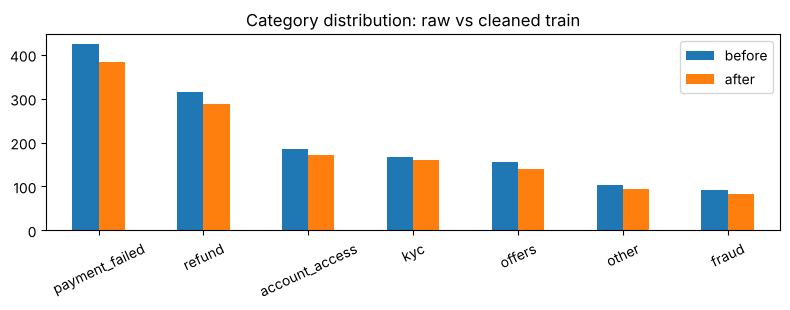

In [18]:
# ---- category distribution before / after, class imbalance ----
def raw_cat(t):
    m = re.search(r'"category": "(\w+)"', t); return m.group(1) if m else None      # also works for truncated labels
before = collections.Counter(raw_cat(r["messages"][2]["content"]) for r in train_raw)
after  = collections.Counter(json.loads(e["target"])["category"] for e in train_clean)
dist = pd.DataFrame({"before": before, "after": after}).fillna(0).astype(int).sort_values("before", ascending=False)
dist["before_%"] = (100 * dist["before"] / dist["before"].sum()).round(1); dist["after_%"] = (100 * dist["after"] / dist["after"].sum()).round(1)
print(dist.to_string())
print(f"\nImbalance ratio (largest/smallest class): before {dist['before'].max()/dist['before'].min():.1f}x, after {dist['after'].max()/dist['after'].min():.1f}x")
print("-> `fraud` is the rarest class (~6%) yet drives P1 + needs_human; `payment_failed` is ~4.7x larger. Cleaning preserved proportions (drops were not class-biased).")
cl_t = [json.loads(e["target"]) for e in train_clean]
for f in ["priority", "language", "needs_human", "channel"]: print(f"{f:12}", dict(collections.Counter(c[f] for c in cl_t)))
print("amount null %:", round(100*sum(c['amount_paise'] is None for c in cl_t)/len(cl_t), 1), "| date null %:", round(100*sum(c['txn_date'] is None for c in cl_t)/len(cl_t), 1))
import matplotlib.pyplot as plt
ax = dist[["before", "after"]].plot.bar(figsize=(8, 3.2), rot=25, title="Category distribution: raw vs cleaned train"); plt.tight_layout(); plt.show()

In [19]:
# Save the audit summary (used by the README/report) and sanity-check the saved log once more
summary = {"original": n0, "valid": n_valid, "defective": n_fix + n_drop, "fixed": n_fix, "dropped": n_drop, "cleaned": n0 - n_drop,
           "defect_occurrences": dict(occ), "category_before": dict(before), "category_after": dict(after),
           "dev_leak_rows": len(leak_ids), "raw_condition_rows": len(train_raw_exp)}
json.dump(summary, open(OUT / "results" / "audit_summary.json", "w"), indent=1)
print(json.dumps(summary, indent=1))

{
 "original": 1445,
 "valid": 1145,
 "defective": 300,
 "fixed": 175,
 "dropped": 125,
 "cleaned": 1320,
 "defect_occurrences": {
  "dev_leakage_verbatim_copy": 30,
  "priority_violates_rules": 60,
  "wrong_key_prio_instead_of_priority": 70,
  "date_not_iso_DDMMYYYY": 30,
  "junk_ticket_unsupported_label": 10,
  "truncated_or_invalid_json": 25,
  "txn_id_not_normalised": 20,
  "amount_in_rupees_not_paise": 25,
  "exact_duplicate": 60
 },
 "category_before": {
  "payment_failed": 425,
  "account_access": 186,
  "refund": 315,
  "fraud": 92,
  "kyc": 168,
  "offers": 155,
  "other": 104
 },
 "category_after": {
  "payment_failed": 384,
  "account_access": 171,
  "refund": 289,
  "fraud": 82,
  "kyc": 160,
  "offers": 140,
  "other": 94
 },
 "dev_leak_rows": 30,
 "raw_condition_rows": 1415
}


## 6. Model selection

| Candidate | Params | Licence / access | Chat template has `system` role? | T4 fit | Verdict |
|---|---|---|---|---|---|
| **Qwen2.5-1.5B-Instruct** | ≈1.54B (1.31B non-embedding) | Apache-2.0, **not gated** | yes (ChatML) | fp16 weights ≈3.1 GB → LoRA fits easily; QLoRA also possible | **Selected** |
| SmolLM2-1.7B-Instruct | ≈1.7B | Apache-2.0, not gated | yes | fits | plausible alternative (slightly larger); *not benchmarked here* |
| Llama-3.2-1B-Instruct | ≈1.2B | Llama community licence, **gated** (needs HF approval/token) | yes | fits | rejected: gated access = reproducibility risk for graders |
| Qwen2.5-3B-Instruct | ≈3.1B | Qwen-research licence (non-commercial) | yes | tight on T4 for 5+ runs in <3h | rejected: licence + time budget |

**Why Qwen2.5-1.5B-Instruct.** (1) Ungated + Apache-2.0 so anyone can reload the adapter; (2) native `system` role, so the *original* system+user messages are used with the model's own template (no workaround to document); (3) Qwen tokenizers split digits individually, which matters for exact copy/arithmetic of 10-digit ids and amounts; (4) 1.5B keeps one epoch short enough that **five training runs + evaluations fit in the 3-hour T4 budget**; (5) it is instruction-tuned, so Baseline 1/2 are meaningful. The choice is a judgement from model properties; I did **not** benchmark the alternatives (the budget does not allow it), and the report says so.

**T4 constraints applied everywhere:** fp16 mixed precision (T4 has no bf16), gradient checkpointing, small micro-batch + gradient accumulation, no flash-attention-2 (needs sm80+; PyTorch SDPA is used).

In [ ]:
from transformers import AutoTokenizer, AutoConfig, AutoModelForCausalLM, BitsAndBytesConfig, TrainingArguments, Trainer, TrainerCallback, set_seed
from accelerate import init_empty_weights
import transformers, peft
print("transformers", transformers.__version__, "| peft", peft.__version__, "| torch", torch.__version__ if torch else None)

tok = AutoTokenizer.from_pretrained(BASE_MODEL)
if tok.pad_token is None: tok.pad_token = tok.eos_token
print("eos:", tok.eos_token, "| pad:", tok.pad_token, "| vocab:", len(tok))

# parameter count WITHOUT downloading weights (meta device) -> verify the <= 4B constraint
with init_empty_weights():
    _m = AutoModelForCausalLM.from_config(AutoConfig.from_pretrained(BASE_MODEL))
N_BASE_PARAMS = sum(p.numel() for p in _m.parameters()); del _m
print(f"base parameters: {N_BASE_PARAMS/1e9:.3f}B")
assert N_BASE_PARAMS <= 4e9, "base model exceeds the 4B limit"

## 7. Chat template and loss masking (Part C)

* The prompt is rendered with the model's **own** chat template (`apply_chat_template(..., add_generation_prompt=True)`) from the original `system` + `user` messages – identical at train and test time.
* Training sequence = `prompt_ids + completion_ids`, where `completion` = the assistant text **plus the end-of-turn token** (so the model learns to stop; generation then ends cleanly and only the JSON is emitted).
* **Loss masking:** `labels = -100` for every prompt token (system + user + generation header); only completion tokens carry loss. I do this myself (instead of TRL's `assistant_only_loss` / `DataCollatorForCompletionOnlyLM`) because those APIs differ across TRL versions and Qwen's template has no `{% generation %}` markers; plain `transformers.Trainer` + PEFT is stable and the masking is **unit-tested below**.
* Prompt and completion are tokenised separately; the boundary (`...assistant\n` | `{"category"...`) is a pre-tokenisation split point for the Qwen tokenizer, and the cell below asserts that separate and joint tokenisation agree.

In [ ]:
def render_prompt(tokenizer, row, system_override=None):
    """Exactly what the model sees at inference: original system + user message, model's own chat template."""
    sys_msg = system_override if system_override is not None else row["messages"][0]["content"]
    msgs = [{"role": "system", "content": sys_msg}, {"role": "user", "content": row["messages"][1]["content"]}]
    return tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)

def tokenize_example(tokenizer, row, target, max_len=None):
    prompt_text = render_prompt(tokenizer, row)
    full_text = tokenizer.apply_chat_template(
        [{"role": "system", "content": row["messages"][0]["content"]}, {"role": "user", "content": row["messages"][1]["content"]},
         {"role": "assistant", "content": target}], tokenize=False)
    assert full_text.startswith(prompt_text), "chat template is not prefix-stable"
    completion_text = full_text[len(prompt_text):].rstrip("\n")           # '<target><end-of-turn token>'
    p_ids = tokenizer(prompt_text, add_special_tokens=False)["input_ids"]
    c_ids = tokenizer(completion_text, add_special_tokens=False)["input_ids"]
    ids = p_ids + c_ids
    if max_len is not None and len(ids) > max_len: return None
    return {"input_ids": ids, "labels": [-100] * len(p_ids) + c_ids, "n_prompt": len(p_ids)}

print(render_prompt(tok, train_clean[0]))
print("-" * 60)
ex = train_clean[0]; t = tokenize_example(tok, ex, ex["target"])
n_p = t["n_prompt"]
full_txt = tok.apply_chat_template([{"role": "system", "content": SYSTEM_PROMPT}, ex["messages"][1], {"role": "assistant", "content": ex["target"]}], tokenize=False)
end_marker = full_txt[len(render_prompt(tok, ex)):].rstrip("\n")[len(ex["target"]):]
# ---- unit tests for the masking ----
assert all(l == -100 for l in t["labels"][:n_p]),               "prompt tokens must be masked"
assert t["labels"][n_p:] == t["input_ids"][n_p:],               "completion tokens must be supervised"
assert tok.decode(t["input_ids"][:n_p]) == render_prompt(tok, ex)
assert tok.decode(t["labels"][n_p:]) == ex["target"] + end_marker and end_marker != "", "supervised span = JSON + end-of-turn token"
print(f"masking OK | prompt tokens masked: {n_p} | supervised tokens: {len(t['labels']) - n_p} | end-of-turn marker: {end_marker!r}")
# joint vs separate tokenisation agreement over the whole cleaned set
mism = 0
for e in train_clean:
    tt = tokenize_example(tok, e, e["target"])
    p = render_prompt(tok, e); fulltxt = tok.apply_chat_template([{"role": "system", "content": SYSTEM_PROMPT}, e["messages"][1], {"role": "assistant", "content": e["target"]}], tokenize=False).rstrip("\n")
    mism += tok(fulltxt, add_special_tokens=False)["input_ids"] != tt["input_ids"]
print("joint-vs-separate tokenisation mismatches:", mism, "of", len(train_clean))

## 8. Token-length analysis → maximum sequence length
The length distribution is **bimodal**: ~97% of tickets are short (median ≈ 200 characters) but ~3% (40 train / 3 dev / **11 test**) are 7–9k-character emails with long quoted threads. These matter: the test set is "deliberately harder", it contains such tickets, and the schema rule "dates inside quoted `>` lines are not the transaction date" is exactly what they exercise. Dropping or truncating them from training would leave the model blind to this pattern (truncation would also cut the supervised JSON), so `MAX_LEN` is set to the **longest training sequence rounded up to a multiple of 64** (cap 4096 as a safety bound), and memory is controlled differently:
* **completion-only logits** – the 152k-vocabulary `lm_head` is applied only to the ~80 supervised positions instead of every position (a 2.5k-token sequence would otherwise need several GB of fp32 logits);
* **length-grouped batches** (`group_by_length=True`) so long sequences are batched together instead of padding short ones to 2.5k tokens.

In [ ]:
import numpy as np
def seq_lens(items): return np.array([len(tokenize_example(tok, e, e["target"])["input_ids"]) for e in items])
L_clean, L_raw = seq_lens(train_clean), seq_lens(train_raw_exp)
prompt_only_test = np.array([len(tok(render_prompt(tok, r), add_special_tokens=False)["input_ids"]) for r in test])
prompt_only_dev  = np.array([len(tok(render_prompt(tok, r), add_special_tokens=False)["input_ids"]) for r in dev])
comp_lens = np.array([len(tokenize_example(tok, e, e["target"])["input_ids"]) - tokenize_example(tok, e, e["target"])["n_prompt"] for e in train_clean])
def pct(a): return {f"p{q}": int(np.percentile(a, q)) for q in (50, 90, 97, 99, 100)}
print("full sequence (prompt+completion), cleaned train:", pct(L_clean), "mean", round(L_clean.mean(), 1))
print("full sequence, raw train                       :", pct(L_raw))
print("completion only (JSON + end token), cleaned    :", pct(comp_lens))
print("prompt only, dev :", pct(prompt_only_dev), "\nprompt only, test:", pct(prompt_only_test))
print("sequences > 512 tokens: clean", int((L_clean > 512).sum()), "| raw", int((L_raw > 512).sum()), "| test prompts", int((prompt_only_test > 512).sum()))
MAX_LEN = min(int(math.ceil(max(L_clean.max(), L_raw.max()) / 64) * 64), 4096)
print(f"\nMAX_LEN = {MAX_LEN}  (examples longer than this: clean={int((L_clean > MAX_LEN).sum())}, raw={int((L_raw > MAX_LEN).sum())}; test prompts longer than longest train sequence: {int((prompt_only_test > MAX_LEN).sum())})")
print(f"Generation budget check: longest gold completion = {comp_lens.max()} tokens <= max_new_tokens=200:", comp_lens.max() <= 200)
assert comp_lens.max() <= 200 and (L_clean <= MAX_LEN).all() and (L_raw <= MAX_LEN).all()
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(10, 2.8)); ax[0].hist(L_clean, bins=50); ax[0].set_title("all training sequences"); ax[1].hist(L_clean[L_clean < 400], bins=40); ax[1].set_title("zoom: < 400 tokens")
for x in ax: x.set_xlabel("tokens")
plt.tight_layout(); plt.show()

## 9. Fine-tuning design – every main setting and why

| Setting | Value | Justification |
|---|---|---|
| Method | **LoRA** (16-bit base, fp16 compute) and **QLoRA** (4-bit NF4, double-quant, fp16 compute) | assignment requirement; both compared in Exp. 2 |
| Rank / alpha | `r=16`, `alpha=2r=32` | 16 is the standard sweet spot for narrow rule-learning tasks; `alpha/r = 2` is held constant when `r` is varied (Exp. 3) so only capacity changes |
| Dropout | 0.05 | light regularisation; ~1.3k examples × 2 epochs gives modest over-fitting risk |
| Target modules | all linear: `q,k,v,o,gate,up,down` | triage needs rule *composition* (MLP-heavy) as well as copying (attention); attention-only is tested in Exp. 4. Trainable ≈ 18.5M at r=16 (computed exactly below) – well under 50M |
| Learning rate | 2e-4, cosine, 5% warmup | usual LoRA range (1e-4…3e-4); warmup avoids early fp16 instability; cosine decays to ~0 within the short run |
| Micro-batch × accumulation | 4 × 4 = effective 16, length-grouped | micro-batch 4 + checkpointing + completion-only logits fits a 15 GB T4 even for the ~2.5k-token threads; effective 16 → ~82 optimizer steps/epoch. If a T4 OOM occurs, lower `HP['bs']` to 2 and raise `grad_accum` to 8 (same effective batch) |
| Epochs | 2 | sized to the 3-hour notebook budget (5 runs); train loss + dev loss per epoch are logged so under-training is visible |
| Weight decay / clip | 0.01 / 1.0 | mild decay; clipping guards fp16 spikes |
| Optimiser | `adamw_torch` (all runs) | only 5–20M trainable params, so optimiser state is negligible; the *same* optimiser in LoRA and QLoRA keeps Exp. 2 a one-variable comparison (paged 8-bit optimisers would be a second variable) |
| Max sequence length | from section 8 (longest training sequence, ≈2.5k tokens) | no truncation; long quoted-thread tickets are kept |
| Seed | 42 everywhere | `set_seed`, data order seeded |

> These are reasoned defaults, **not tuned on dev**; dev is used only to *measure* (and for the rank experiment, which the assignment asks for).

## 10. Reusable pipeline: model loading, LoRA/QLoRA, training, generation, scoring

In [ ]:
ALL_LINEAR = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]
ATTN_ONLY  = ["q_proj", "k_proj", "v_proj", "o_proj"]
HP = dict(epochs=2, lr=2e-4, bs=4, grad_accum=4, warmup_ratio=0.05, weight_decay=0.01, dropout=0.05, max_grad_norm=1.0)
# Plain generation protocol required by the assignment. We pass ONLY do_sample=False and max_new_tokens=200 (+pad id);
# everything else comes from the model's generation_config exactly as a grader's plain `model.generate` call would.
GEN_KW = dict(do_sample=False, max_new_tokens=200)

import importlib.util
_spec = importlib.util.spec_from_file_location("score_mod", PACK / "score.py"); score_mod = importlib.util.module_from_spec(_spec); _spec.loader.exec_module(score_mod)

def require_gpu():
    if not HAS_GPU: raise RuntimeError("This cell needs the Colab T4 GPU (Runtime > Change runtime type > T4 GPU).")

def free_gpu():
    gc.collect()
    if torch is not None and torch.cuda.is_available(): torch.cuda.empty_cache(); torch.cuda.synchronize()

def gpu_report(tag=""):
    a, pk, rs = torch.cuda.memory_allocated()/2**30, torch.cuda.max_memory_allocated()/2**30, torch.cuda.max_memory_reserved()/2**30
    print(f"[GPU {tag}] allocated={a:.2f} GiB | peak allocated={pk:.2f} GiB | peak reserved={rs:.2f} GiB")

def load_base(quant4=False):
    require_gpu()
    kw = dict(device_map={"": 0})
    if quant4:
        kw["quantization_config"] = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True,
                                                       bnb_4bit_compute_dtype=torch.float16)
    try:    model = AutoModelForCausalLM.from_pretrained(BASE_MODEL, dtype=torch.float16, **kw)        # transformers >= 4.56
    except TypeError: model = AutoModelForCausalLM.from_pretrained(BASE_MODEL, torch_dtype=torch.float16, **kw)
    return model

@torch.no_grad()
def generate_outputs(model, rows, batch_size=16, system_override=None, desc="generate"):
    """Greedy generation from the ORIGINAL system+user messages via the chat template. Returns {id: stripped raw text}."""
    model.eval(); model.config.use_cache = True
    tok.padding_side = "left"
    order = sorted(range(len(rows)), key=lambda i: len(rows[i]["messages"][1]["content"]))     # length-sorted batches = less padding
    outs, t0 = {}, time.time()
    for s in range(0, len(order), batch_size):
        idx = order[s:s + batch_size]
        enc = tok([render_prompt(tok, rows[i], system_override) for i in idx], return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
        gen = model.generate(**enc, pad_token_id=tok.pad_token_id, **GEN_KW)
        for j, i in enumerate(idx):
            outs[rows[i]["id"]] = tok.decode(gen[j, enc["input_ids"].shape[1]:], skip_special_tokens=True).strip()   # ONLY .strip() post-processing
        if (s // batch_size) % 4 == 0: print(f"  {desc}: {min(s + batch_size, len(order))}/{len(order)} ({time.time() - t0:.0f}s)", end="\r")
    print(f"  {desc}: done {len(order)} in {time.time() - t0:.0f}s" + " " * 20)
    return outs

def score_outputs(gold_rows, outs, tag):
    """Write score.py-format prediction file, run the ORIGINAL score.py (CLI) and also keep its machine-readable dict."""
    pred_rows = [{"id": g["id"], "output": outs.get(g["id"], "")} for g in gold_rows]
    p = OUT / "predictions" / f"dev_{tag}.jsonl"; save_jsonl(pred_rows, p)
    res = score_mod.score(gold_rows, pred_rows)
    cli = subprocess.run([sys.executable, str(PACK / "score.py"), "--gold", str(PACK / "data/dev.jsonl"), "--pred", str(p)], capture_output=True, text=True).stdout
    (OUT / "logs" / f"score_{tag}.txt").write_text(cli)
    return res, cli, p

def headline(res):
    a = res["all"]; return {"json_valid": a["json_valid"], "exact_match": a["exact_match"], "mean_field_acc": a["mean_field_acc"], "fields": a["fields"]}

In [ ]:
# ---- Tokenised datasets (built once). RAW uses raw label strings, CLEANED uses audited strings. Dev is only used for validation loss. ----
import torch
class SFTData(torch.utils.data.Dataset):
    def __init__(self, items): self.items = items
    def __len__(self): return len(self.items)
    def __getitem__(self, i): return self.items[i]

def build_dataset(examples):
    toks = [tokenize_example(tok, e, e["target"], max_len=MAX_LEN) for e in examples]
    assert all(t is not None for t in toks), "an example exceeds MAX_LEN"
    return SFTData([{"input_ids": t["input_ids"], "labels": t["labels"]} for t in toks])

def make_collator(pad_id):
    def collate(batch):
        L = max(len(b["input_ids"]) for b in batch)
        ids = torch.full((len(batch), L), pad_id, dtype=torch.long); lab = torch.full((len(batch), L), -100, dtype=torch.long); att = torch.zeros((len(batch), L), dtype=torch.long)
        for i, b in enumerate(batch):
            n = len(b["input_ids"]); ids[i, :n] = torch.tensor(b["input_ids"]); lab[i, :n] = torch.tensor(b["labels"]); att[i, :n] = 1
        return {"input_ids": ids, "attention_mask": att, "labels": lab}
    return collate

DATASETS = {"clean": build_dataset(train_clean), "raw": build_dataset(train_raw_exp)}
dev_for_loss = build_dataset([{"id": d["id"], "messages": d["messages"][:2], "target": d["messages"][2]["content"]} for d in dev])   # validation loss only
print({k: len(v) for k, v in DATASETS.items()}, "| dev (loss only):", len(dev_for_loss))

In [ ]:
class MemLogger(TrainerCallback):
    """GPU-memory monitoring: records peak allocated memory with every logged step."""
    def on_log(self, args, state, control, logs=None, **kw):
        if logs is not None and torch.cuda.is_available(): logs["gpu_peak_gib"] = round(torch.cuda.max_memory_allocated() / 2**30, 3)

import torch.nn.functional as F
def completion_loss(model, batch):
    """Causal-LM loss computed ONLY on supervised positions. The decoder runs on the full sequence, but the 152k-vocab lm_head is applied
    just to positions whose next-token label != -100. Mathematically identical to the standard shifted cross-entropy with ignore_index=-100."""
    inner = getattr(model, "module", model).base_model.model            # PeftModel -> LoraModel -> Qwen2ForCausalLM
    h = inner.model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"], use_cache=False).last_hidden_state
    tgt = batch["labels"][:, 1:]; keep = tgt != -100
    logits = inner.lm_head(h[:, :-1][keep]).float()
    return F.cross_entropy(logits, tgt[keep])

class CompletionLossTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        loss = completion_loss(model, inputs)
        return (loss, None) if return_outputs else loss

class DevLossCallback(TrainerCallback):
    """Validation loss on the dev set at the end of every epoch (loss only; dev labels never produce gradients)."""
    def __init__(self, ds): self.ds = ds
    def on_epoch_end(self, args, state, control, model=None, **kw):
        was_training = model.training; model.eval(); col = make_collator(tok.pad_token_id); tot, n = 0.0, 0
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
            for s in range(0, len(self.ds), 4):
                b = {k: v.to(model.device) for k, v in col([self.ds[i] for i in range(s, min(s + 4, len(self.ds)))]).items()}
                tot += completion_loss(model, b).item() * b["input_ids"].shape[0]; n += b["input_ids"].shape[0]
        model.train(was_training)
        state.log_history.append({"eval_loss": tot / n, "epoch": state.epoch, "step": state.global_step}); print(f"  dev loss @ epoch {state.epoch:.0f}: {tot / n:.4f}")

def train_run(name, cfg):
    """One full experiment: load -> (Q)LoRA -> train -> measure -> save adapter -> dev generation -> score. Cached on Drive."""
    require_gpu()
    res_path, ad_dir = OUT / "results" / f"{name}.json", OUT / "adapters" / name
    if res_path.exists() and (ad_dir / "adapter_model.safetensors").exists():
        print(f"[{name}] cached result found on Drive - skipping (delete {res_path.name} to re-run)"); return json.load(open(res_path))
    print(f"\n===== {name} =====\n{cfg}")
    set_seed(SEED); free_gpu(); torch.cuda.reset_peak_memory_stats()
    model = load_base(quant4=cfg["quant4"])
    from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
    if cfg["quant4"]:
        model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True, gradient_checkpointing_kwargs={"use_reentrant": False})
    else:
        model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False}); model.enable_input_require_grads()
    model.config.use_cache = False
    lcfg = LoraConfig(r=cfg["r"], lora_alpha=2 * cfg["r"], lora_dropout=HP["dropout"], bias="none", task_type="CAUSAL_LM", target_modules=cfg["targets"])
    model = get_peft_model(model, lcfg)
    for p in model.parameters():
        if p.requires_grad: p.data = p.data.float()            # fp32 adapters -> valid fp16 AMP grad-scaling
    n_train = sum(p.numel() for p in model.parameters() if p.requires_grad); n_total = sum(p.numel() for p in model.parameters())
    print(f"trainable params: {n_train:,} ({100 * n_train / n_total:.3f}% of {n_total:,})"); assert n_train < 50_000_000, "trainable-parameter limit violated"
    args = TrainingArguments(output_dir=str(WORK / "ckpt" / name), per_device_train_batch_size=HP["bs"], per_device_eval_batch_size=8,
        gradient_accumulation_steps=HP["grad_accum"], num_train_epochs=cfg["epochs"], learning_rate=cfg["lr"], lr_scheduler_type="cosine",
        warmup_ratio=HP["warmup_ratio"], weight_decay=HP["weight_decay"], max_grad_norm=HP["max_grad_norm"], fp16=True, optim="adamw_torch",
        logging_steps=10, save_strategy="no", report_to="none", seed=SEED, data_seed=SEED, remove_unused_columns=False, dataloader_num_workers=0,
        group_by_length=True)
    trainer = CompletionLossTrainer(model=model, args=args, train_dataset=DATASETS[cfg["data"]],
                                    data_collator=make_collator(tok.pad_token_id), callbacks=[MemLogger(), DevLossCallback(dev_for_loss)])
    t0 = time.time(); trainer.train(); train_min = (time.time() - t0) / 60
    peak_alloc, peak_res = torch.cuda.max_memory_allocated() / 2**30, torch.cuda.max_memory_reserved() / 2**30   # measured BEFORE generation
    gpu_report(f"{name} after training"); print(f"training time: {train_min:.2f} min")
    ad_dir.mkdir(parents=True, exist_ok=True); model.save_pretrained(str(ad_dir))
    json.dump(trainer.state.log_history, open(OUT / "logs" / f"trainlog_{name}.json", "w"), indent=1)
    # dev evaluation in the same setting the model was trained in (4-bit for QLoRA)
    model.gradient_checkpointing_disable()
    outs = generate_outputs(model, dev, batch_size=16, desc=f"{name} dev")
    res, cli, pp = score_outputs(dev, outs, name); print(cli)
    result = {"name": name, "cfg": {k: v for k, v in cfg.items()}, "trainable_params": n_train, "total_params": n_total, "peak_gpu_alloc_gib": round(peak_alloc, 3),
              "peak_gpu_reserved_gib": round(peak_res, 3), "train_minutes": round(train_min, 2), "n_train_examples": len(DATASETS[cfg["data"]]),
              "optimizer_steps": trainer.state.global_step, "dev": headline(res), "dev_pred_file": str(pp),
              "final_train_loss": next((h["loss"] for h in reversed(trainer.state.log_history) if "loss" in h), None),
              "eval_losses": [h["eval_loss"] for h in trainer.state.log_history if "eval_loss" in h], "dev_fp16": None, "by_category": {k: v["exact_match"] for k, v in res.items() if k.startswith("category=")}}
    del trainer, model; free_gpu()
    if cfg["quant4"]:      # a grader loads the base in fp16: also measure the QLoRA adapter on an fp16 base
        base = load_base(False); from peft import PeftModel
        m = PeftModel.from_pretrained(base, str(ad_dir)); outs16 = generate_outputs(m, dev, 16, desc=f"{name} dev (fp16 base)")
        res16, cli16, pp16 = score_outputs(dev, outs16, name + "_fp16base"); print("QLoRA adapter evaluated on an fp16 base:\n", cli16)
        result["dev_fp16"] = headline(res16); result["dev_fp16_pred_file"] = str(pp16); del m, base; free_gpu()
    else:
        result["dev_fp16"] = result["dev"]; result["dev_fp16_pred_file"] = result["dev_pred_file"]
    json.dump(result, open(res_path, "w"), indent=1)
    return result

## 11. PART B – Baselines (no fine-tuning, same base model, all 200 dev rows)
* **Baseline 1:** base model + the original fixed system prompt + the ticket.
* **Baseline 2:** same model, but the *entire* `SCHEMA.md` (rules + example record) is appended to the system prompt. **Allowed here only as a reference point**; it is never used in training-time targets or final inference.

Both use the identical greedy protocol and are scored by the original `score.py`. Outputs are scored raw: if the model wraps JSON in markdown fences or chatter, that counts as invalid JSON (no repair).

In [ ]:
def run_baseline(tag, system_override):
    require_gpu(); cache = OUT / "results" / f"{tag}.json"
    if cache.exists(): print(f"[{tag}] cached"); return json.load(open(cache))
    free_gpu(); model = load_base(False)
    outs = generate_outputs(model, dev, batch_size=8, system_override=system_override, desc=tag)
    res, cli, p = score_outputs(dev, outs, tag); print(cli)
    r = {"name": tag, "dev": headline(res), "by_category": {k: v["exact_match"] for k, v in res.items() if k.startswith("category=")}, "sample_outputs": [outs[d["id"]] for d in dev[:3]],
         "generation_config": str(model.generation_config)}
    json.dump(r, open(cache, "w"), indent=1); del model; free_gpu(); return r

RULES_SYSTEM = SYSTEM_PROMPT + "\n\nBusiness rules (labelling specification):\n\n" + SCHEMA_TEXT
b1 = run_baseline("baseline1_base_fixed_prompt", None)
b2 = run_baseline("baseline2_base_with_schema_rules", RULES_SYSTEM)
print("Base model generation_config actually used by model.generate:\n", b1["generation_config"])
for b in (b1, b2): print(b["name"], "sample raw outputs:", [o[:150] for o in b["sample_outputs"][:2]])

In [ ]:
def md_table(headers, rows):
    out = ["| " + " | ".join(headers) + " |", "|" + "|".join("---" for _ in headers) + "|"]
    out += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]; return "\n".join(out)
pc = lambda x: f"{100 * x:.1f}%"
def baseline_table(bs):
    rows = [[b["name"], pc(b["dev"]["json_valid"]), pc(b["dev"]["exact_match"]), pc(b["dev"]["mean_field_acc"])] + [pc(b["dev"]["fields"][k]) for k in KEYS] for b in bs]
    return md_table(["run", "JSON valid", "exact", "mean field"] + KEYS, rows)
print(baseline_table([b1, b2]))
print("\nCategory-wise exact match:")
cats = sorted(b1["by_category"]); print(md_table(["category"] + [b["name"] for b in (b1, b2)], [[c.split("=")[1]] + [pc(b["by_category"][c]) for b in (b1, b2)] for c in cats]))

**How to read the two baselines (fill in from the numbers above).** Baseline 1 shows what the pretrained model knows about the *task* with no rules – expect poor `priority`, `needs_human`, `amount_paise` (unit conversion), `txn_date` (relative dates) and possibly format failures, because nothing tells it the schema's thresholds or the paise convention. Baseline 2 shows how much of that gap is *knowledge of the rules* (fixable by a prompt) versus *ability to execute them* (arithmetic, date maths, ignoring distractors) – the part that fine-tuning must teach a 1.5B model. The difference between the two is the headroom that rules-in-prompt buys; fine-tuning has to beat Baseline 1 and ideally approach or exceed Baseline 2 **without** the long rule prompt.

## 12. PART C/D – Training runs and the four controlled experiments

All runs share: base model, seed 42, tokenisation, `MAX_LEN`, optimiser, schedule, effective batch 16, 2 epochs, evaluation protocol. **Each experiment changes exactly one variable relative to the reference run `E0`:**

| Assignment experiment | Run | Single variable changed vs `E0` |
|---|---|---|
| (reference) | `E0` | cleaned data · 16-bit LoRA · r=16 · all-linear · lr 2e-4 |
| 1. raw vs cleaned data | `E1` | **targets: raw label strings** (1,415 rows; truncated/mis-keyed/mis-formatted labels left as-is; only the 30 dev-copies excluded) vs cleaned (1,320 rows). Same epochs → ≈7% more optimizer steps for raw |
| 2. LoRA vs QLoRA | `E2` | **base precision: 4-bit NF4 (QLoRA)** instead of 16-bit |
| 3. hyper-parameter | `E3` | **LoRA rank 4** instead of 16 (alpha = 2r, so the scale is unchanged) |
| 4. own idea | `E4` | **target modules: attention-only (q,k,v,o)** instead of all linear layers. *Rationale from the data audit:* the hard fields are rule composition + unit conversion + date arithmetic (MLP-heavy computation) rather than copying; if attention alone suffices the adapter is ~4× smaller, otherwise the MLP adapters are doing the rule work |

> **Budget.** Rough expectation on a T4: ~10–25 min per run (**unmeasured estimate** – real times are logged). Each finished run is cached on Drive, so after a disconnect simply re-run this cell: finished runs are skipped, the interrupted one restarts. To stay safely inside 3 h, set `RUN = ["E0_..."]` first, check timing, then add the others.

In [ ]:
EXPERIMENTS = {
    "E0_cleaned_lora16bit_r16":         dict(data="clean", quant4=False, r=16, targets=ALL_LINEAR, lr=HP["lr"], epochs=HP["epochs"], desc="Reference: cleaned data, 16-bit LoRA, r=16, all-linear"),
    "E1_raw_lora16bit_r16":             dict(data="raw",   quant4=False, r=16, targets=ALL_LINEAR, lr=HP["lr"], epochs=HP["epochs"], desc="Exp1: RAW (unaudited) targets instead of cleaned"),
    "E2_cleaned_qlora4bit_r16":         dict(data="clean", quant4=True,  r=16, targets=ALL_LINEAR, lr=HP["lr"], epochs=HP["epochs"], desc="Exp2: 4-bit NF4 QLoRA instead of 16-bit LoRA"),
    "E3_cleaned_lora16bit_r4":          dict(data="clean", quant4=False, r=4,  targets=ALL_LINEAR, lr=HP["lr"], epochs=HP["epochs"], desc="Exp3: LoRA rank 4 instead of 16 (alpha=2r)"),
    "E4_cleaned_lora16bit_r16_attnonly":dict(data="clean", quant4=False, r=16, targets=ATTN_ONLY,  lr=HP["lr"], epochs=HP["epochs"], desc="Exp4: attention-only target modules instead of all linear"),
}
RUN = list(EXPERIMENTS)          # e.g. RUN = ["E0_cleaned_lora16bit_r16"] for a first timing check
# exact LoRA parameter counts from the config arithmetic (hidden 1536, intermediate 8960, 28 layers, 12 heads, 2 kv heads) – verified at runtime by train_run's assert
def lora_params(r, targets, h=1536, i=8960, kv=256, layers=28):
    shape = {"q_proj": (h, h), "k_proj": (h, kv), "v_proj": (h, kv), "o_proj": (h, h), "gate_proj": (h, i), "up_proj": (h, i), "down_proj": (i, h)}
    return layers * sum(r * (a + b) for t, (a, b) in shape.items() if t in targets)
for n, c in EXPERIMENTS.items(): print(f"{n:38} expected trainable LoRA params ~ {lora_params(c['r'], c['targets'])/1e6:.2f}M")

In [ ]:
import traceback
NB_T0 = time.time(); all_results = {}
for name in RUN:
    try:
        all_results[name] = train_run(name, EXPERIMENTS[name])
    except Exception as e:      # a failed experiment is recorded, never silently ignored
        tb = traceback.format_exc(); print(tb)
        json.dump({"name": name, "status": "FAILED", "error": repr(e), "traceback": tb}, open(OUT / "results" / f"{name}.FAILED.json", "w"), indent=1)
        free_gpu()
print(f"\nelapsed this session: {(time.time() - NB_T0) / 60:.1f} min")

## 13. Experiment comparison table (measured values only, read back from the saved result files)

In [ ]:
def load_results():
    out = {}
    for name in EXPERIMENTS:
        p, f = OUT / "results" / f"{name}.json", OUT / "results" / f"{name}.FAILED.json"
        out[name] = json.load(open(p)) if p.exists() else ({"status": "FAILED"} if f.exists() else None)
    return out
R = load_results()
rows, csv_rows = [], []
for name, cfg in EXPERIMENTS.items():
    r = R[name]
    if r is None or r.get("status") == "FAILED":
        rows.append([name, cfg["desc"], "NOT RUN" if r is None else "FAILED", "-", "-", "-"]); continue
    em_cell = pc(r["dev"]["exact_match"]) + (f" [fp16-base: {pc(r['dev_fp16']['exact_match'])}]" if cfg["quant4"] else "")
    mf_cell = pc(r["dev"]["mean_field_acc"]) + (f" [fp16-base: {pc(r['dev_fp16']['mean_field_acc'])}]" if cfg["quant4"] else "")
    rows.append([name, cfg["desc"], em_cell, mf_cell, f"{r['peak_gpu_alloc_gib']:.2f}", f"{r['train_minutes']:.1f}"])
    csv_rows.append({"experiment": name, "what_changed": cfg["desc"], "dev_exact_match": r["dev"]["exact_match"], "dev_mean_field_acc": r["dev"]["mean_field_acc"],
                     "dev_json_valid": r["dev"]["json_valid"], "peak_gpu_alloc_gib": r["peak_gpu_alloc_gib"], "peak_gpu_reserved_gib": r["peak_gpu_reserved_gib"],
                     "train_minutes": r["train_minutes"], "trainable_params": r["trainable_params"], "optimizer_steps": r["optimizer_steps"], "n_train_examples": r["n_train_examples"],
                     "dev_exact_match_fp16_base": r["dev_fp16"]["exact_match"], "dev_mean_field_fp16_base": r["dev_fp16"]["mean_field_acc"]})
EXP_TABLE = md_table(["Experiment", "What changed", "Dev exact match", "Dev mean field acc", "Peak GPU (GiB, allocated)", "Train (min)"], rows)
print(EXP_TABLE)
if csv_rows: pd.DataFrame(csv_rows).to_csv(OUT / "experiment_results.csv", index=False)

# Paired comparisons + the noise floor: 200 dev rows -> one row = 0.5 pp; binomial SE of exact match ~ sqrt(p(1-p)/200)
PAIRS = [("Exp1 raw vs cleaned", "E1_raw_lora16bit_r16", "E0_cleaned_lora16bit_r16"), ("Exp2 QLoRA vs LoRA", "E2_cleaned_qlora4bit_r16", "E0_cleaned_lora16bit_r16"),
         ("Exp3 rank 4 vs 16", "E3_cleaned_lora16bit_r4", "E0_cleaned_lora16bit_r16"), ("Exp4 attn-only vs all-linear", "E4_cleaned_lora16bit_r16_attnonly", "E0_cleaned_lora16bit_r16")]
PAIR_SENTENCES = []
for label, a, b in PAIRS:
    if R[a] and R[b] and "dev" in R[a] and "dev" in R[b]:
        da, db = R[a], R[b]; d = 100 * (da["dev"]["exact_match"] - db["dev"]["exact_match"]); p = db["dev"]["exact_match"]; se = 100 * math.sqrt(p * (1 - p) / 200)
        s = (f"{label}: dev exact match {pc(da['dev']['exact_match'])} vs {pc(db['dev']['exact_match'])} (delta {d:+.1f} pp; single-seed SE of one run ~ {se:.1f} pp -> "
             f"{'larger than' if abs(d) > 2 * se else 'within'} ~2 SE); peak GPU {da['peak_gpu_alloc_gib']:.2f} vs {db['peak_gpu_alloc_gib']:.2f} GiB; time {da['train_minutes']:.1f} vs {db['train_minutes']:.1f} min; "
             f"trainable params {da['trainable_params']/1e6:.2f}M vs {db['trainable_params']/1e6:.2f}M")
        PAIR_SENTENCES.append(s); print("-", s)

In [ ]:
# Training curves from the saved logs (loss monitoring)
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for name in EXPERIMENTS:
    p = OUT / "logs" / f"trainlog_{name}.json"
    if not p.exists(): continue
    h = json.load(open(p)); tl = [(x["step"], x["loss"]) for x in h if "loss" in x]; el = [(x["step"], x["eval_loss"]) for x in h if "eval_loss" in x]
    ax[0].plot(*zip(*tl), label=name[:3]); ax[1].plot(*zip(*el), marker="o", label=name[:3])
ax[0].set_title("train loss (completion tokens)"); ax[1].set_title("dev loss per epoch (validation only)")
for a in ax: a.set_xlabel("optimizer step"); a.legend()
plt.tight_layout(); plt.show()

### Interpretation (to be written from the measured table above – these are the points to defend in the interview)
* **Exp 1 (data quality).** Look at which fields move: raw labels contain wrong priorities (60 rows), a different key name (70 rows), non-ISO dates, un-normalised ids, rupee-valued amounts and truncated JSON. The model imitates whatever it is shown, so expect raw-trained outputs to reproduce *some* of these formatting defects (check `json_valid`, `txn_date`, `txn_id`, `amount_paise`, `priority` per-field columns in `score_*` logs). Whether the dev-EM gap exceeds the ±~3 pp noise floor is what the paired-comparison line says – if it does not, report it as inconclusive rather than as a win.
* **Exp 2 (LoRA vs QLoRA).** Compare *peak GPU* and *minutes*: 4-bit shrinks base weights (~3.1 GB → ~1 GB) but adds de-quantisation overhead per step, so time usually goes **up** while memory goes **down**; quality can drop slightly because the adapter was trained against quantised weights – hence the extra fp16-base evaluation.
* **Exp 3 (rank).** The adapter learns a narrow mapping; if r=4 matches r=16, capacity is not the bottleneck and the cheaper adapter is preferable; if it is worse, rule composition needs more capacity.
* **Exp 4 (target modules).** If attention-only is close to all-linear, copying/attending dominates; a clear gap supports the MLP-does-the-rules hypothesis.

## 14. Best-model selection, adapter saving, reload verification

In [ ]:
# Selection rule (fixed in advance): highest dev exact match on an FP16 base (that is how a grader will load it), ties -> mean field acc -> lower peak memory.
R = load_results(); done = [r for r in R.values() if r and "dev" in r]
assert done, "no finished experiment - run section 12 first"
ranked = sorted(done, key=lambda r: (-r["dev_fp16"]["exact_match"], -r["dev_fp16"]["mean_field_acc"], r["peak_gpu_alloc_gib"]))
for r in ranked: print(f"{r['name']:38} fp16-base dev EM={pc(r['dev_fp16']['exact_match'])} MFA={pc(r['dev_fp16']['mean_field_acc'])} mem={r['peak_gpu_alloc_gib']:.2f}GiB")
BEST = ranked[0]; print("\nBEST:", BEST["name"])

FINAL_AD = OUT / "final" / "adapter"; FINAL_AD.mkdir(parents=True, exist_ok=True)
for f in ["adapter_config.json", "adapter_model.safetensors"]: shutil.copy(OUT / "adapters" / BEST["name"] / f, FINAL_AD / f)
print("final adapter files:", {p.name: f"{p.stat().st_size/2**20:.1f} MiB" for p in FINAL_AD.iterdir()})
cfg_ad = json.load(open(FINAL_AD / "adapter_config.json"))
print({k: cfg_ad[k] for k in ["peft_type", "base_model_name_or_path", "r", "lora_alpha", "lora_dropout", "target_modules", "task_type"]})
assert cfg_ad["peft_type"] == "LORA" and cfg_ad["base_model_name_or_path"] == BASE_MODEL
from safetensors import safe_open
with safe_open(str(FINAL_AD / "adapter_model.safetensors"), framework="pt") as f:
    N_ADAPTER = sum(f.get_tensor(k).numel() for k in f.keys())
print(f"adapter tensor elements = trainable parameters: {N_ADAPTER:,}  (< 50,000,000: {N_ADAPTER < 50_000_000})"); assert N_ADAPTER < 50_000_000

In [ ]:
# Reload verification: a FRESH fp16 base + the adapter loaded only from the saved files (what a grader does).
from peft import PeftModel
@torch.no_grad()
def generate_one(model, row):
    enc = tok(render_prompt(tok, row), return_tensors="pt", add_special_tokens=False).to(model.device)
    g = model.generate(**enc, pad_token_id=tok.pad_token_id, **GEN_KW)
    return tok.decode(g[0, enc["input_ids"].shape[1]:], skip_special_tokens=True).strip()

def load_final_model():
    free_gpu(); base = load_base(False); m = PeftModel.from_pretrained(base, str(FINAL_AD)); m.eval(); m.config.use_cache = True; return m
final_model = load_final_model()
print("loaded OK | trainable (should be 0 in inference mode):", sum(p.numel() for p in final_model.parameters() if p.requires_grad))
saved_dev = {json.loads(l)["id"]: json.loads(l)["output"] for l in open(BEST["dev_fp16_pred_file"])}
sub = dev[:40]; t0 = time.time()
re_out = {r["id"]: generate_one(final_model, r) for r in sub}
same = sum(re_out[r["id"]] == saved_dev[r["id"]] for r in sub)
print(f"reload check: bs=1 outputs from the reloaded adapter match the saved batched (bs=16) dev predictions on {same}/{len(sub)} rows ({time.time()-t0:.0f}s)")
print("(differences, if any, come from fp16 numerics of padded batches vs single sequences - not from the adapter)")
RELOAD_MATCH = (same, len(sub))

## 15. PART E – Error analysis of the best model on dev

In [ ]:
best_out = {json.loads(l)["id"]: json.loads(l)["output"] for l in open(BEST["dev_fp16_pred_file"])}
res_best, cli_best, _ = score_outputs(dev, best_out, "BEST_final_dev"); print(cli_best)
gold = {d["id"]: json.loads(d["messages"][-1]["content"]) for d in dev}; dev_by_id = {d["id"]: d for d in dev}

def amounts_in(text):
    vals = set()
    for s in sentences(strip_dates(text)):
        for p in AMT_PATTERNS:
            for m in p.finditer(s): vals.add(parse_amount(m.group(1), m.group(2)))
    return vals
def distractor_amounts(text):
    vals = set()
    for p in DISTRACTORS[:3]: vals |= amounts_in(" ".join(m.group(0) for m in p.finditer(text)))
    return vals

def diagnose(field, g, p, row, pred_obj):
    rec, src, body = split_ticket(row["messages"][1]["content"]); text = clean_body(body)
    if field == "amount_paise":
        if p is None: return "missed the amount (predicted null)"
        if g is None: return "hallucinated an amount (gold null)"
        if not isinstance(p, int): return "wrong JSON type for amount"
        if p * 100 == g or g * 100 == p: return "x100 unit/scale error (rupees vs paise)"
        if p in distractor_amounts(text): return "copied a distractor amount (balance/limit)"
        if re.search(r"\d\s*(k|lakh)", text, re.I): return "k/lakh shorthand mis-converted"
        if g % 100: return "decimal rupees/paise handling"
        return "digit-level copy/arithmetic error"
    if field == "txn_date":
        if p is None: return "missed the date (predicted null)"
        if g is None: return "hallucinated a date (gold null)"
        try:
            dg, dp = date.fromisoformat(g), date.fromisoformat(p)
            if dg.day == dp.month and dg.month == dp.day: return "day/month swapped"
            if dg.year != dp.year and dg.replace(year=dp.year) == dp: return "wrong year for year-less date"
            return f"date arithmetic/resolution off by {abs((dg - dp).days)} day(s)"
        except Exception: return "malformed date"
    if field == "txn_id":
        if p is None: return "missed the transaction id (predicted null)"
        if g is None: return "hallucinated a transaction id (gold null)"
        d = sum(a != b for a, b in zip(str(g), str(p))) + abs(len(str(g)) - len(str(p)))
        return f"digit error(s) while copying/normalising id ({d} char diff)"
    if field == "channel":
        if p is None: return "missed an explicitly stated channel"
        if g is None: return f"inferred channel '{p}' that is not explicitly stated"
        return f"confused channels ({g} vs {p})"
    if field == "language": return "Hinglish/English misjudged" + (" (very short or mostly-English ticket)" if len(text) < 90 else "")
    if field == "needs_human":
        prior = bool(PRIOR.search(text)); return ("missed a prior-contact phrase" if (g and not p and prior) else "needs_human inconsistent with priority/prior-contact rule")
    if field == "priority":
        exp = derive_priority(pred_obj.get("category"), pred_obj.get("amount_paise"), bool(LEGAL.search(text)))
        return "cascade: priority is wrong although consistent with predicted category/amount" if exp == p else "priority rule mis-applied (threshold / legal threat / category)"
    if field == "category": return f"category confusion: gold {g} -> predicted {p}"
    return "mismatch"
FIX_HINT = {
 "amount": "targeted augmentation of k/lakh/decimal and distractor-amount tickets; add more epochs",
 "date": "synthetic relative/year-less date examples (kal/parso, N days ago, year boundary); consider rank/epoch increase",
 "id": "more id-normalisation examples (hyphen/space variants); id digits are copy-bound -> check attention-only vs all-linear gap",
 "channel": "audit-style negative examples: tickets that mention 'card'/'top up' without naming a mode",
 "lang": "balanced Hinglish/English short tickets",
 "needs": "oversample prior-contact phrasings (second complaint, teesri baar, written N times)",
 "prior": "oversample prior-contact phrasings", "prio": "oversample threshold cases (just below/above Rs 5,000 / 50,000) and legal-threat variants",
 "categ": "oversample boundary categories (account_access vs other PIN how-to, fraud vs refund duplicates)"}
def hint_for(field): return FIX_HINT.get({"amount_paise": "amount", "txn_date": "date", "txn_id": "id", "channel": "channel", "language": "lang", "needs_human": "needs", "priority": "prio", "category": "categ"}.get(field, ""), "more targeted data")

errors, json_fail = [], []
for d in dev:
    out = best_out[d["id"]]; pobj = score_mod.parse(out)
    if pobj is None: json_fail.append((d["id"], out[:160])); continue
    for k in KEYS:
        if not (k in pobj and score_mod.same(pobj[k], gold[d["id"]][k])): errors.append((d["id"], k, gold[d["id"]][k], pobj.get(k, "<missing>"), diagnose(k, gold[d["id"]][k], pobj.get(k), d, pobj)))
    if set(pobj) != set(KEYS): errors.append((d["id"], "KEYSET", sorted(KEYS), sorted(pobj), "extra/missing keys"))
print(f"JSON-invalid outputs: {len(json_fail)} -> {json_fail[:3]}")
print(f"total field errors: {len(errors)} across {len({e[0] for e in errors})} dev rows (of 200)\n")
fe = collections.Counter(e[1] for e in errors)
print("Weakest fields (errors / 200):", dict(fe.most_common()))
print("Weakest categories (exact match):", dict(sorted(((k.split('=')[1], round(v['exact_match'], 3)) for k, v in res_best.items() if k.startswith('category=')), key=lambda x: x[1])))
print("\nMost frequent error types:"); [print(f"  {c:3d}  {k[1]:<13} {k[0]}") for k, c in collections.Counter((e[4].split(' (')[0].split(': ')[0], e[1]) for e in errors).most_common(12)]

In [ ]:
# >= 10 specific failures: real dev rows, chosen round-robin over the weakest fields (never fabricated). Reasons are rule-based DIAGNOSES of
# the real mismatch (see diagnose()) - read them, and refine the wording in the report with your own judgement.
by_field = collections.defaultdict(list)
for e in errors: by_field[e[1]].append(e)
picked, order_f = [], [f for f, _ in fe.most_common()]
while len(picked) < 12 and any(by_field[f] for f in order_f):
    for f in order_f:
        if by_field[f] and len(picked) < 12: picked.append(by_field[f].pop(0))
FAIL_ROWS, FAIL_MD = [], []
for (i, f, g, p, why) in picked:
    d = dev_by_id[i]; rec, src, body = split_ticket(d["messages"][1]["content"]); txt = " ".join(clean_body(body).split())
    FAIL_ROWS.append([i, f, str(g), str(p), why, hint_for(f)])
    FAIL_MD.append(f"**{i}** (Received {rec}, {src}) · field `{f}`\n- input: {txt[:330]}\n- expected `{g}` · predicted `{p}`\n- reason: {why}\n- improvement: {hint_for(f)}\n")
print(f"{len(picked)} failures selected" + ("" if len(picked) >= 10 else f"  (NOTE: the model made fewer than 10 field errors on dev; all are shown - nothing is invented)"))
print("\n".join(FAIL_MD))
FAIL_TABLE = md_table(["Ticket", "Field", "Expected", "Predicted", "Reason (diagnosis)", "Possible improvement"], FAIL_ROWS)
(OUT / "final" / "failures_full.md").write_text("\n".join(FAIL_MD))

### One additional week – what I would do (prioritised by expected value)
1. **Quantify noise before claiming wins:** 3 seeds per configuration + paired bootstrap on the 200 dev rows (one row = 0.5 pp; single-seed SE ≈ 3 pp) so experiment deltas are credible.
2. **Targeted rule-based augmentation** (allowed: uses only `train.jsonl` + `SCHEMA.md`): synthesise tickets for the slices where errors concentrate above (k/lakh/decimal amounts with distractors, year-less dates around a year boundary, hyphenated/spaced ids, legal-threat and prior-contact phrasings). The test set is "deliberately harder", so coverage of rare surface forms matters more than more epochs of the same data.
3. **Adversarial validation on inputs only** (train vs test ticket text, no labels): a classifier that separates them shows *which* surface features shift, guiding (2) without touching test labels.
4. **Longer training with a loss-based stopping rule** (3–4 epochs, evaluate dev loss every 40 steps) and a small LR sweep {1e-4, 2e-4, 3e-4}.
5. **Boundary-category review:** PIN how-to (`account_access` vs `other`) and double-charge (`refund` vs `fraud`) are schema-ambiguous; ask the data owner for a decision rule and relabel consistently.
6. **Try Qwen2.5-3B-Instruct with QLoRA** if licence permits for this use (research licence) – only if (1)–(2) leave a clear gap, since it roughly doubles runtime.

## 16. Final test inference → `predictions_test.jsonl`
* Model: **fresh fp16 base + the saved final adapter** (not the in-memory trained model) – so the file is reproducible from the saved artifacts.
* Input: exactly the original `system` + `user` messages through the model's own chat template; **no rules, no examples**.
* `model.generate`, greedy (`do_sample=False`), `max_new_tokens=200`, **batch size 1** (no padding effects). Only `.strip()` is applied. No JSON repair, no field filling, no other model/API.
* Progress is appended to a partial file on Drive after every row, so a Colab disconnect only costs the unfinished rows.

In [ ]:
PRED_TEST = OUT / "final" / "predictions_test.jsonl"; PARTIAL = OUT / "final" / "predictions_test.partial.jsonl"
done = {json.loads(l)["id"]: json.loads(l)["output"] for l in open(PARTIAL)} if PARTIAL.exists() else {}
print(f"resuming with {len(done)} rows already generated")
t0 = time.time()
with open(PARTIAL, "a", encoding="utf-8") as f:
    for n, r in enumerate(test):
        if r["id"] in done: continue
        done[r["id"]] = generate_one(final_model, r)                      # raw model text, .strip() only
        f.write(json.dumps({"id": r["id"], "output": done[r["id"]]}, ensure_ascii=False) + "\n"); f.flush()
        if n % 25 == 0: print(f"  {len(done)}/{len(test)}  ({time.time() - t0:.0f}s)", end="\r")
save_jsonl([{"id": r["id"], "output": done[r["id"]]} for r in test], PRED_TEST)       # same order as test_inputs.jsonl
print(f"\nwrote {PRED_TEST} in {(time.time() - t0) / 60:.1f} min this session")

In [ ]:
# ---- Structural checks on the prediction file ----
P = load_jsonl(PRED_TEST); test_ids = [r["id"] for r in test]
assert len(P) == 400 and [p["id"] for p in P] == test_ids and len({p["id"] for p in P}) == 400, "id mismatch / duplicates / missing"
assert all(set(p) == {"id", "output"} and isinstance(p["output"], str) for p in P)
assert all(p["output"] == p["output"].strip() for p in P), "outputs must only be whitespace-stripped"
valid = [score_mod.parse(p["output"]) for p in P]
ok_keys = sum(o is not None and set(o) == set(KEYS) for o in valid)
print(f"records={len(P)} | unique ids={len({p['id'] for p in P})} | JSON-valid (diagnostic only): {sum(o is not None for o in valid)}/400 | exactly the 8 keys: {ok_keys}/400")
print("longest output (chars):", max(len(p["output"]) for p in P), "| outputs not ending in '}':", sum(not p["output"].endswith("}") for p in P))
print("category mix of predictions:", dict(collections.Counter(o["category"] for o in valid if o)))
TEST_VALID = sum(o is not None for o in valid)

In [ ]:
# ---- Reproducibility self-check (the grader regenerates a random sample): fresh model object, random 20 test rows ----
del final_model; free_gpu(); final_model = load_final_model()
sample = random.Random(SEED).sample(test, 20); pred_map = {p["id"]: p["output"] for p in P}
rep_same = sum(generate_one(final_model, r) == pred_map[r["id"]] for r in sample)
print(f"regenerated {rep_same}/{len(sample)} random test predictions identically from a freshly loaded base+adapter")
REPRO = (rep_same, len(sample))

In [ ]:
# ---- Sensitivity diagnostic: default generation_config (what plain generate uses) vs repetition_penalty=1.0 ----
print("generation_config in effect:", final_model.generation_config)
subd = dev[:40]; a = {r["id"]: generate_one(final_model, r) for r in subd}
GEN_KW["repetition_penalty"] = 1.0
b = {r["id"]: generate_one(final_model, r) for r in subd}; del GEN_KW["repetition_penalty"]
agree = sum(a[k] == b[k] for k in a)
print(f"outputs identical with vs without the model's default repetition_penalty on {agree}/{len(subd)} dev rows")
print("-> report this: if a grader's generate call differs in repetition_penalty, up to", len(subd) - agree, "of 40 outputs could differ.")
SENS = (agree, len(subd))

## 17. Submission assembly, validation, and README/report generation

In [ ]:
# Re-assert the audit numbers that the report/README text states statically (guards against silent drift if the audit code is edited).
S = json.load(open(OUT / "results" / "audit_summary.json"))
assert (S["original"], S["valid"], S["fixed"], S["dropped"], S["cleaned"]) == (1445, 1145, 175, 125, 1320), S
R = load_results(); BEST_R = R[BEST["name"]]; bc = BEST_R["cfg"]
N_ADAPTER_M = f"{N_ADAPTER/1e6:.2f}M"
best_method = "QLoRA (4-bit NF4 during training; evaluated and inferred on an fp16 base)" if bc["quant4"] else "16-bit LoRA"
n_cat_rows = sorted(((k.split("=")[1], v["exact_match"]) for k, v in res_best.items() if k.startswith("category=")), key=lambda x: x[1])
worst_fields = ", ".join(f"`{k}` ({v} errors)" for k, v in fe.most_common(4)) or "none"
ERROR_SUMMARY = (f"Dev exact match {pc(res_best['all']['exact_match'])}; JSON-invalid outputs: {len(json_fail)}/200. Field errors by count: {worst_fields}. "
                 f"Weakest categories (exact match): " + ", ".join(f"{c} {pc(v)}" for c, v in n_cat_rows[:3]) + ". Most frequent diagnosed error types: " +
                 "; ".join(f"{k[0]} on `{k[1]}` ×{c}" for k, c in collections.Counter((e[4].split(' (')[0].split(': ')[0], e[1]) for e in errors).most_common(4)) +
                 ". Each failure below is a real dev row; *reasons are rule-based diagnoses of the actual mismatch – refine them with your own reading.*")
fill = {
 "N_BASE": f"{N_BASE_PARAMS/1e9:.2f}", "BASELINE_TABLE": md_table(["run", "JSON valid", "exact", "mean field"], [[b["name"], pc(b["dev"]["json_valid"]), pc(b["dev"]["exact_match"]), pc(b["dev"]["mean_field_acc"])] for b in (b1, b2)]),
 "BASELINE_NOTE": f"Rules in the prompt change exact match from {pc(b1['dev']['exact_match'])} to {pc(b2['dev']['exact_match'])} (JSON validity {pc(b1['dev']['json_valid'])} → {pc(b2['dev']['json_valid'])}), separating *knowing* the rules from *executing* them.",
 "MAXSEQ": str(int(max(L_clean.max(), L_raw.max()))), "MAX_LEN": str(MAX_LEN), "EXPERIMENT_TABLE": EXP_TABLE,
 "PAIR_SENTENCES": "\n".join("- " + s for s in PAIR_SENTENCES),
 "INTERPRETATION": "Mechanistically: 4-bit weights cut memory but add de-quantisation cost; a smaller rank or attention-only adapter tests whether capacity or MLP-based rule composition limits accuracy; raw-label training can only copy the defects it is shown. Interpret each delta against the noise floor above – [EDIT: add your reading of the table before submitting].",
 "BEST_NAME": BEST["name"], "BEST_EM": pc(BEST["dev_fp16"]["exact_match"]), "BEST_MFA": pc(BEST["dev_fp16"]["mean_field_acc"]), "BEST_METHOD": best_method,
 "RELOAD_NOTE": f"bs=1 outputs match the saved dev predictions on {RELOAD_MATCH[0]}/{RELOAD_MATCH[1]} rows (rest = fp16 padding numerics).", "REPRO_NOTE": f"{REPRO[0]}/{REPRO[1]} random test predictions regenerated identically from a freshly loaded base+adapter.",
 "TEST_VALID": str(TEST_VALID), "ERROR_SUMMARY": ERROR_SUMMARY, "FAILURES_TABLE": FAIL_TABLE,
 "AI_TOOLS": "Claude (Anthropic) was used as a coding/writing assistant: to draft the audit checker and data-cleaning pipeline, the Colab notebook code, and the first drafts of README/report. The generated code and every number were run and checked by me; the audit decisions and interpretations are mine to defend. [CONFIRM/EDIT this statement so it matches what you actually did.]",
 "LOADED_4BIT": "No for evaluation/inference (fp16 base). " + ("Training used 4-bit NF4 (QLoRA)." if bc["quant4"] else "Training also used a 16-bit base (plain LoRA); QLoRA was only run as Experiment 2."),
 "BEST_R": str(bc["r"]), "BEST_ALPHA": str(2 * bc["r"]), "BEST_TARGETS": "all linear layers (q,k,v,o,gate,up,down)" if bc["targets"] == ALL_LINEAR else "attention only (q,k,v,o)",
 "N_ADAPTER": f"{N_ADAPTER:,}", "SENS_NOTE": f"{SENS[0]}/{SENS[1]} outputs identical with vs without that default repetition penalty.",
}
def render(t):
    for k, v in fill.items(): t = t.replace("{{" + k + "}}", str(v))
    left = re.findall(r"\{\{[A-Z_]+\}\}", t); assert not left, left; return t
(OUT / "final" / "report.md").write_text(render(REPORT_TEMPLATE), encoding="utf-8")
(OUT / "final" / "README.md").write_text(render(README_TEMPLATE), encoding="utf-8")
words = len(re.findall(r"\S+", (OUT / "final" / "report.md").read_text()))
print(f"report.md written: {words} words (compact 3-page budget is roughly 1,700 words incl. tables; trim the failures table if you exceed it)")

In [ ]:
# ---- Assemble the exact submission structure and validate the ACTUAL contents ----
SUB = OUT / "final" / "submission" / "VIMA3YA-LLM-FineTuning"
if SUB.exists(): shutil.rmtree(SUB)
(SUB / "adapter").mkdir(parents=True); (SUB / "logs").mkdir()
for f in ["adapter_config.json", "adapter_model.safetensors"]: shutil.copy(FINAL_AD / f, SUB / "adapter" / f)
shutil.copy(OUT / "final" / "README.md", SUB / "README.md"); shutil.copy(OUT / "final" / "report.md", SUB / "report.md")
shutil.copy(OUT / "cleaning_log.csv", SUB / "cleaning_log.csv"); shutil.copy(PRED_TEST, SUB / "predictions_test.jsonl")
shutil.copy(OUT / "experiment_results.csv", SUB / "experiment_results.csv"); shutil.copy(OUT / "final" / "failures_full.md", SUB / "logs" / "failures_full.md")
for p in list((OUT / "logs").glob("*")) + list((OUT / "results").glob("*.json")): shutil.copy(p, SUB / "logs" / p.name)
nb_saved = [p for p in [OUT / "notebook.ipynb", Path("notebook.ipynb")] if p.exists()]
if nb_saved: shutil.copy(nb_saved[0], SUB / "notebook.ipynb")
else: print("REMINDER: File > Download > .ipynb (after this cell finishes so outputs are included), save as notebook.ipynb into", SUB)

checks = {}
checks["train/dev/test counts 1445/200/400"] = (len(train_raw), len(dev), len(test)) == (1445, 200, 400)
lg = pd.read_csv(SUB / "cleaning_log.csv"); checks["cleaning_log columns + actions + real ids"] = list(lg.columns) == ["id", "action", "reason"] and set(lg.action) <= {"fix", "drop"} and set(lg.id) <= set(by_id)
checks["cleaned labels follow SCHEMA (validated)"] = all(not validate_record(json.loads(e["target"]), e["messages"][1]["content"]) for e in train_clean)
checks["no dev text in training data"] = not ({e["messages"][1]["content"] for e in train_clean + train_raw_exp} & set(dev_texts))
checks["base params <= 4B"] = N_BASE_PARAMS <= 4e9
checks["adapter trainable < 50M"] = N_ADAPTER < 50_000_000
checks["adapter files present (PEFT format)"] = (SUB / "adapter/adapter_config.json").exists() and (SUB / "adapter/adapter_model.safetensors").exists()
checks[">=4 experiments measured"] = sum(1 for r in R.values() if r and "dev" in r) >= 4
checks["experiment table matches saved logs"] = all(abs(pd.read_csv(SUB / "experiment_results.csv").set_index("experiment").loc[n, "dev_exact_match"] - r["dev"]["exact_match"]) < 1e-9 for n, r in R.items() if r and "dev" in r)
PT = load_jsonl(SUB / "predictions_test.jsonl"); checks["predictions: exactly 400, ids == test ids, no dups"] = len(PT) == 400 and [p["id"] for p in PT] == test_ids and len({p["id"] for p in PT}) == 400
checks["README/report/notebook present"] = all((SUB / f).exists() for f in ["README.md", "report.md"]) and bool(nb_saved)
checks["report within page budget (heuristic <=1700 words)"] = words <= 1700
checks["no raw data files in submission"] = not any(p.name in {"train.jsonl", "dev.jsonl", "test_inputs.jsonl"} for p in SUB.rglob("*"))
checks["no HF tokens / API keys in text files"] = not any(re.search(r"hf_[A-Za-z0-9]{20,}|sk-[A-Za-z0-9]{20,}", p.read_text(errors="ignore")) for p in SUB.rglob("*") if p.suffix in {".md", ".json", ".csv", ".jsonl", ".txt", ".ipynb"})
for k, v in checks.items(): print("PASS" if v else "FAIL", "-", k)
shutil.make_archive(str(OUT / "VIMA3YA_submission_bundle"), "zip", SUB.parent, SUB.name)
print("\nbundle:", OUT / "VIMA3YA_submission_bundle.zip", "| total session minutes:", round((time.time() - NB_T0) / 60, 1))

### After the run – checklist
1. File → Download → **.ipynb** (outputs included) and place it as `notebook.ipynb` in the submission folder (re-run the last cell so the bundle contains it).
2. Read `report.md`: replace every `[EDIT: ...]` / `[CONFIRM/EDIT ...]` marker with your own analysis; check the failure diagnoses against the tickets.
3. Push to a **private** GitHub repository (adapter ≈ tens of MB < 100 MB; no Git LFS needed unless larger). Do **not** add the data files. Make it public only inside the 1-hour window after the deadline.